# MLB Clutch Metric — Historical + Live Jupyter Notebook

This notebook builds one row per plate appearance, identifies both hitter and pitcher, calculates context-adjusted run value, learns situation importance from Statcast win-expectancy changes, and produces hitter/pitcher situation and player summaries.

**Historical:** Retrosheet play-by-play (1908–2025). **Current season:** Baseball Savant Statcast. **Identity:** Chadwick Bureau Register. Raw observations are stored as Parquet; DuckDB is used for large-scale queries so the entire history does not have to fit into RAM.

In [2]:
# Run once in a new Jupyter environment
%pip install -q pandas numpy pyarrow requests tqdm pybaseball duckdb

from pathlib import Path
from datetime import date, timedelta
import io, zipfile, requests
import numpy as np
import pandas as pd
from tqdm import tqdm

from pybaseball import statcast, chadwick_register
import duckdb

import time
import requests
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

Note: you may need to restart the kernel to use updated packages.


In [3]:


BASE = Path.cwd() / 'mlb_clutch_data'
PLAY_DIR = BASE / 'plays'
PA_DIR = BASE / 'pa'
AUX_DIR = BASE / 'aux'
SUMMARY_DIR = BASE / 'summaries'
for p in [PLAY_DIR, PA_DIR, AUX_DIR, SUMMARY_DIR]: p.mkdir(parents=True, exist_ok=True)

HISTORY_START = 1908
RETROSHEET_END = 2025
CURRENT_YEAR = date.today().year
LIVE_LOOKBACK_DAYS = 2
HISTORY_START_YEAR = 1908
HISTORY_END_YEAR = 2025


In [4]:
import warnings

warnings.filterwarnings(
    "ignore",
    message=".*errors='ignore' is deprecated.*",
    category=FutureWarning
)

## 1. Why this is two data sources

Retrosheet is the historical backbone. Its parsed play-by-play contains the game ID, inning, inning half, score before the play, batter, pitcher, outs, pre/post runners, PA/AB flags, runs, results, and a pinch-hit flag. Statcast supplies modern pitch-level data and explicit run/win expectancy changes. Keep the source in a `data_source` column so results are auditable.

In [6]:
RETRO_URL = 'https://www.retrosheet.org/downloads/plays/{year}plays.zip'

# Preserve play ordering/date columns when the source provides them.
# If older cached play files do not have date/pn, the state-preparation
# function below uses stable source-row order and derives game_date from gid.
NEEDED = [
    'gid', 'date', 'pn', 'event', 'inning', 'top_bot', 'vis_home',
    'batteam', 'pitteam', 'score_v', 'score_h', 'batter', 'pitcher',
    'bathand', 'pithand', 'pa', 'ab', 'single', 'double', 'triple', 'hr',
    'sh', 'sf', 'hbp', 'walk', 'k', 'iw', 'xi', 'roe', 'fc', 'othout',
    'noout', 'outs_pre', 'outs_post', 'br1_pre', 'br2_pre', 'br3_pre',
    'br1_post', 'br2_post', 'br3_post', 'runs', 'rbi', 'bat_f', 'pbp'
]

def download_retrosheet_year(year, overwrite=False):
    out = PLAY_DIR / f'retrosheet_{year}.parquet'
    if out.exists() and not overwrite:
        return out
    r = requests.get(RETRO_URL.format(year=year), timeout=180)
    r.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(r.content)) as z:
        names = [n for n in z.namelist() if n.lower().endswith('.csv')]
        if not names:
            raise RuntimeError(f'No CSV in {year} Retrosheet archive')
        name = max(names, key=lambda n: z.getinfo(n).file_size)
        with z.open(name) as f:
            df = pd.read_csv(f, low_memory=False)
    for c in NEEDED:
        if c not in df.columns:
            df[c] = pd.NA
    df = df[NEEDED].copy()
    df['season'] = year
    df['pbp_quality'] = df['pbp'].astype('string')
    for c in ['gid', 'batter', 'pitcher', 'br1_pre', 'br2_pre', 'br3_pre',
              'br1_post', 'br2_post', 'br3_post']:
        df[c] = df[c].astype('string')
    df.to_parquet(out, index=False)
    return out

# Test first:
# download_retrosheet_year(2025, overwrite=True)

# Full historical source backfill, only if needed:
# for y in range(HISTORY_START_YEAR, HISTORY_END_YEAR + 1):
#     download_retrosheet_year(y, overwrite=True)


## 2. Player identity crosswalk

Retrosheet uses historical player IDs while Statcast uses MLBAM IDs. The Chadwick Register links these systems and provides a stable UUID-like identity. This lets career results be grouped across eras.

In [8]:
# ============================================================
# 3. CHADWICK REGISTER
# ============================================================

import pandas as pd
import requests
from io import BytesIO

CHADWICK_DIR = AUX_DIR / "chadwick"
CHADWICK_DIR.mkdir(parents=True, exist_ok=True)

CHADWICK_BASE = (
    "https://raw.githubusercontent.com/"
    "chadwickbureau/register/master/data/"
)


def load_chadwick_register(force_download=False):

    cache_file = CHADWICK_DIR / "people.parquet"

    if cache_file.exists() and not force_download:
        print("Loading cached Chadwick Register...")
        register = pd.read_parquet(cache_file)
        print(f"{len(register):,} people loaded.")
        return register

    parts = []

    for shard in "0123456789abcdef":

        url = CHADWICK_BASE + f"people-{shard}.csv"

        print(f"Downloading people-{shard}.csv ...")

        response = requests.get(
            url,
            timeout=180
        )

        response.raise_for_status()

        part = pd.read_csv(
            BytesIO(response.content),
            low_memory=False
        )

        parts.append(part)

    register = pd.concat(
        parts,
        ignore_index=True
    )

    required = [
        "key_uuid",
        "key_retro",
        "key_mlbam"
    ]

    missing = [
        column
        for column in required
        if column not in register.columns
    ]

    if missing:
        print("Missing columns:", missing)
        print("Available columns:")
        print(register.columns.tolist())

        raise ValueError(
            "Chadwick Register schema is missing "
            "one or more required identity fields."
        )

    for column in [
        "key_uuid",
        "key_person",
        "key_retro",
        "key_mlbam",
        "key_bbref",
        "key_fangraphs"
    ]:

        if column in register.columns:
            register[column] = (
                register[column]
                .astype("string")
            )

    register["player_name"] = (
        register["name_first"]
        .fillna("")
        .str.strip()
        + " "
        + register["name_last"]
        .fillna("")
        .str.strip()
    )

    register["player_name"] = (
        register["player_name"]
        .str.replace(
            r"\s+",
            " ",
            regex=True
        )
        .str.strip()
    )

    register.to_parquet(
        cache_file,
        index=False
    )

    print()
    print("================================")
    print("CHADWICK REGISTER LOADED")
    print("================================")
    print(f"People: {len(register):,}")
    print(f"Saved: {cache_file}")

    return register


register = load_chadwick_register(
    force_download=True
)

print(register.columns.tolist())


CHADWICK REGISTER LOADED
People: 526,894
Saved: C:\Users\blobf\OneDrive\MLB Clutch\mlb_clutch_data\aux\chadwick\people.parquet
['key_person', 'key_uuid', 'key_mlbam', 'key_retro', 'key_bbref', 'key_bbref_minors', 'key_fangraphs', 'key_npb', 'key_sr_nfl', 'key_sr_nba', 'key_sr_nhl', 'key_wikidata', 'name_last', 'name_first', 'name_given', 'name_suffix', 'name_matrilineal', 'name_nick', 'birth_year', 'birth_month', 'birth_day', 'death_year', 'death_month', 'death_day', 'pro_played_first', 'pro_played_last', 'mlb_played_first', 'mlb_played_last', 'col_played_first', 'col_played_last', 'pro_managed_first', 'pro_managed_last', 'mlb_managed_first', 'mlb_managed_last', 'col_managed_first', 'col_managed_last', 'pro_umpired_first', 'pro_umpired_last', 'mlb_umpired_first', 'mlb_umpired_last', 'player_name']


In [9]:
# ============================================================
# CREATE PLAYER ID CROSSWALKS
# ============================================================

retro_map = (
    register[
        [
            "key_retro",
            "key_uuid",
            "key_mlbam",
            "player_name"
        ]
    ]
    .dropna(
        subset=["key_retro"]
    )
    .drop_duplicates(
        subset=["key_retro"]
    )
    .rename(
        columns={
            "key_retro": "retro_id",
            "key_uuid": "person_uuid",
            "key_mlbam": "mlbam_id"
        }
    )
)


mlbam_map = (
    register[
        [
            "key_mlbam",
            "key_uuid",
            "player_name"
        ]
    ]
    .dropna(
        subset=["key_mlbam"]
    )
    .drop_duplicates(
        subset=["key_mlbam"]
    )
    .rename(
        columns={
            "key_mlbam": "mlbam_id",
            "key_uuid": "person_uuid"
        }
    )
)


print(
    "Retrosheet IDs:",
    len(retro_map)
)

print(
    "MLBAM IDs:",
    len(mlbam_map)
)

Retrosheet IDs: 25799
MLBAM IDs: 135208


## 3. Historical RE24-style outcome value

For historical records, use the run-expectancy framework:

`run_value = runs_on_play + RE_after - RE_before`

This makes a single with runners on second/third and two outs different from a single with the bases empty. 

In [11]:
# ============================================================
# PREPARE RETROSHEET PLAYS FOR RE24
# ============================================================

def has_runner(series):
    """
    True when a Retrosheet runner ID exists.
    """
    s = series.astype("string")

    return (
        s.notna()
        & s.ne("")
        & s.ne("nan")
        & s.ne("<NA>")
    )


def prepare_historical_states(df):
    """
    Create all game-state variables needed for RE24.

    This function uses ALL plays in Retrosheet, not only PA rows.
    """

    df = df.copy()

    # --------------------------------------------------------
    # Basic numeric fields
    # --------------------------------------------------------

    df["inning"] = pd.to_numeric(
        df["inning"],
        errors="coerce"
    )

    df["top_bot"] = pd.to_numeric(
        df["top_bot"],
        errors="coerce"
    )

    df["score_v"] = pd.to_numeric(
        df["score_v"],
        errors="coerce"
    ).fillna(0)

    df["score_h"] = pd.to_numeric(
        df["score_h"],
        errors="coerce"
    ).fillna(0)

    df["outs_pre"] = pd.to_numeric(
        df["outs_pre"],
        errors="coerce"
    ).fillna(0).astype(int)

    df["outs_post"] = pd.to_numeric(
        df["outs_post"],
        errors="coerce"
    ).fillna(
        df["outs_pre"]
    ).astype(int)

    df["runs"] = pd.to_numeric(
        df["runs"],
        errors="coerce"
    ).fillna(0)

    # --------------------------------------------------------
    # Sort plays in true within-game order where possible.
    # Older cached files may not have pn; in that case preserve the
    # original CSV/Parquet row order within game/inning/half.
    # --------------------------------------------------------

    df["_source_order_for_sort"] = np.arange(len(df))
    if "pn" in df.columns:
        pn_numeric = pd.to_numeric(df["pn"], errors="coerce")
    else:
        pn_numeric = pd.Series(np.nan, index=df.index)

    if pn_numeric.notna().any():
        df["pn"] = pn_numeric
        df = df.sort_values(
            ["gid", "pn", "_source_order_for_sort"],
            kind="stable",
            na_position="last"
        ).copy()
    else:
        df = df.sort_values(
            ["gid", "inning", "top_bot", "_source_order_for_sort"],
            kind="stable"
        ).copy()

    # --------------------------------------------------------
    # BASE STATE BEFORE PLAY
    #
    # 100 = runner on first
    # 010 = runner on second
    # 001 = runner on third
    # 110 = first + second
    # --------------------------------------------------------

    df["base_state_pre"] = (
        has_runner(df["br1_pre"])
        .astype(int)
        .astype(str)
        +
        has_runner(df["br2_pre"])
        .astype(int)
        .astype(str)
        +
        has_runner(df["br3_pre"])
        .astype(int)
        .astype(str)
    )

    # --------------------------------------------------------
    # BASE STATE AFTER PLAY
    # --------------------------------------------------------

    df["base_state_post"] = (
        has_runner(df["br1_post"])
        .astype(int)
        .astype(str)
        +
        has_runner(df["br2_post"])
        .astype(int)
        .astype(str)
        +
        has_runner(df["br3_post"])
        .astype(int)
        .astype(str)
    )

    # --------------------------------------------------------
    # HALF-INNING ID
    # --------------------------------------------------------

    df["half_id"] = (
        df["gid"].astype("string")
        + "_"
        + df["inning"].astype("Int64").astype(str)
        + "_"
        + df["top_bot"].astype("Int64").astype(str)
    )

    # --------------------------------------------------------
    # RUNS REMAINING IN HALF-INNING
    # --------------------------------------------------------

    df["runs_to_half_end"] = (
        df.groupby("half_id")["runs"]
        .transform(
            lambda x:
                x.iloc[::-1]
                 .cumsum()
                 .iloc[::-1]
        )
    )

    # Runs remaining after current play
    df["runs_after_play"] = (
        df["runs_to_half_end"]
        - df["runs"]
    )

    # --------------------------------------------------------
    # SCORE BEFORE PLAY
    # --------------------------------------------------------

    # top_bot = 0 -> away/visitor bats
    # top_bot = 1 -> home bats

    df["bat_score_before"] = np.where(
        df["top_bot"].eq(0),
        df["score_v"],
        df["score_h"]
    )

    df["fld_score_before"] = np.where(
        df["top_bot"].eq(0),
        df["score_h"],
        df["score_v"]
    )

    # --------------------------------------------------------
    # RUN DIFFERENTIAL FROM BATTER'S PERSPECTIVE
    # --------------------------------------------------------

    df["run_diff"] = (
        df["bat_score_before"]
        -
        df["fld_score_before"]
    )

    # --------------------------------------------------------
    # RISP
    # --------------------------------------------------------

    df["risp"] = (
        has_runner(df["br2_pre"])
        |
        has_runner(df["br3_pre"])
    )

    # --------------------------------------------------------
    # SCORE AFTER PLAY
    # --------------------------------------------------------

    df["away_score_after"] = (
        df["score_v"]
        +
        np.where(
            df["top_bot"].eq(0),
            df["runs"],
            0
        )
    )

    df["home_score_after"] = (
        df["score_h"]
        +
        np.where(
            df["top_bot"].eq(1),
            df["runs"],
            0
        )
    )

    # --------------------------------------------------------
    # IS THIS THE LAST PLAY OF THE GAME?
    # --------------------------------------------------------

    if "pn" in df.columns:

        final_play_number = (
            df.groupby("gid")["pn"]
            .transform("max")
        )

        df["is_game_end"] = (
            df["pn"]
            ==
            final_play_number
        )

    else:

        row_number = (
            df.groupby("gid")
            .cumcount()
        )

        total_rows = (
            df.groupby("gid")["gid"]
            .transform("size")
        )

        df["is_game_end"] = (
            row_number
            ==
            total_rows - 1
        )

    # --------------------------------------------------------
    # FINAL GAME SCORE
    # --------------------------------------------------------

    final_scores = (
        df.loc[
            df["is_game_end"],
            [
                "gid",
                "home_score_after",
                "away_score_after"
            ]
        ]
        .drop_duplicates(
            subset=["gid"]
        )
        .rename(
            columns={
                "home_score_after":
                    "final_home_score",

                "away_score_after":
                    "final_away_score"
            }
        )
    )

    df = df.merge(
        final_scores,
        on="gid",
        how="left"
    )

    # --------------------------------------------------------
    # HOME TEAM WIN
    # --------------------------------------------------------

    df["home_win"] = np.where(
        df["final_home_score"]
        >
        df["final_away_score"],
        1,

        np.where(
            df["final_home_score"]
            <
            df["final_away_score"],
            0,
            np.nan
        )
    )

    # --------------------------------------------------------
    # PRE-PLAY STATE KEY
    #
    # inning | score differential | half | outs | bases
    # --------------------------------------------------------

    score_diff_for_state = (
        df["run_diff"]
        .clip(-10, 10)
    )

    df["state_key_pre"] = (
        df["inning"]
        .astype("Int64")
        .astype(str)

        + "|"

        + score_diff_for_state
        .astype("Int64")
        .astype(str)

        + "|"

        + df["top_bot"]
        .astype("Int64")
        .astype(str)

        + "|"

        + df["outs_pre"]
        .astype("Int64")
        .astype(str)

        + "|"

        + df["base_state_pre"]
    )

    # --------------------------------------------------------
    # STATE AFTER PLAY
    # --------------------------------------------------------

    df["inning_post"] = df["inning"]

    df["top_bot_post"] = df["top_bot"]

    df["outs_post_state"] = df["outs_post"]

    df["base_state_post_state"] = (
        df["base_state_post"]
    )

    inning_finished = (
        df["outs_post"] >= 3
    )

    active_game = (
        ~df["is_game_end"]
    )

    # Top half -> bottom half
    top_to_bottom = (
        inning_finished
        &
        active_game
        &
        df["top_bot"].eq(0)
    )

    # Bottom half -> top of next inning
    bottom_to_top = (
        inning_finished
        &
        active_game
        &
        df["top_bot"].eq(1)
    )

    df.loc[
        top_to_bottom,
        "top_bot_post"
    ] = 1

    df.loc[
        bottom_to_top,
        "top_bot_post"
    ] = 0

    df.loc[
        bottom_to_top,
        "inning_post"
    ] = (
        df.loc[
            bottom_to_top,
            "inning"
        ]
        + 1
    )

    # New half inning begins empty
    reset_state = (
        inning_finished
        &
        active_game
    )

    df.loc[
        reset_state,
        "outs_post_state"
    ] = 0

    df.loc[
        reset_state,
        "base_state_post_state"
    ] = "000"

    # --------------------------------------------------------
    # SCORE DIFFERENTIAL AFTER PLAY
    # --------------------------------------------------------

    df["bat_score_after"] = np.where(
        df["top_bot_post"].eq(0),
        df["away_score_after"],
        df["home_score_after"]
    )

    df["fld_score_after"] = np.where(
        df["top_bot_post"].eq(0),
        df["home_score_after"],
        df["away_score_after"]
    )

    df["run_diff_post"] = (
        df["bat_score_after"]
        -
        df["fld_score_after"]
    )

    # --------------------------------------------------------
    # POST-PLAY STATE KEY
    # --------------------------------------------------------

    df["state_key_post"] = (
        df["inning_post"]
        .astype("Int64")
        .astype(str)

        + "|"

        + df["run_diff_post"]
        .clip(-10, 10)
        .astype("Int64")
        .astype(str)

        + "|"

        + df["top_bot_post"]
        .astype("Int64")
        .astype(str)

        + "|"

        + df["outs_post_state"]
        .astype("Int64")
        .astype(str)

        + "|"

        + df["base_state_post_state"]
    )

    return df

In [12]:
def build_retable(
    start_year=HISTORY_START_YEAR,
    end_year=HISTORY_END_YEAR
):
    """
    Build the historical Run Expectancy (RE24) table
    from all Retrosheet play-by-play data.
    """

    pre_parts = []
    post_parts = []

    for year in tqdm(
        range(start_year, end_year + 1),
        desc="Building RE24",
        unit="season"
    ):

        print(f"\nProcessing {year}...")

        path = PLAY_DIR / f"retrosheet_{year}.parquet"

        # Download the season if it isn't already present
        if not path.exists():
            download_retrosheet_year(year)

        # Load ALL plays for the season
        df = pd.read_parquet(path)

        # Create game-state information
        df = prepare_historical_states(df)

        # -----------------------------
        # BEFORE-PLAY RUN EXPECTANCY
        # -----------------------------

        pre = (
            df.groupby("state_key_pre")["runs_to_half_end"]
            .agg(
                run_sum="sum",
                n="count"
            )
            .reset_index()
        )

        pre = pre.rename(
            columns={
                "state_key_pre": "state_key"
            }
        )

        # -----------------------------
        # AFTER-PLAY RUN EXPECTANCY
        # -----------------------------

        post = (
            df.groupby("state_key_post")["runs_after_play"]
            .agg(
                run_sum="sum",
                n="count"
            )
            .reset_index()
        )

        post = post.rename(
            columns={
                "state_key_post": "state_key"
            }
        )

        pre_parts.append(pre)
        post_parts.append(post)

    # Combine all seasons
    pre_all = pd.concat(
        pre_parts,
        ignore_index=True
    )

    post_all = pd.concat(
        post_parts,
        ignore_index=True
    )

    # Aggregate across all seasons
    pre = (
        pre_all
        .groupby("state_key")[
            ["run_sum", "n"]
        ]
        .sum()
        .reset_index()
    )

    post = (
        post_all
        .groupby("state_key")[
            ["run_sum", "n"]
        ]
        .sum()
        .reset_index()
    )

    # Calculate expected runs
    pre["RE_before"] = (
        pre["run_sum"] /
        pre["n"]
    )

    post["RE_after"] = (
        post["run_sum"] /
        post["n"]
    )

    # Combine
    re_table = (
        pre[
            ["state_key", "RE_before"]
        ]
        .merge(
            post[
                ["state_key", "RE_after"]
            ],
            on="state_key",
            how="outer"
        )
    )

    # Save the table
    output_file = (
        AUX_DIR /
        "re24_table.parquet"
    )

    re_table.to_parquet(
        output_file,
        index=False
    )

    print("\n================================")
    print("RE24 TABLE COMPLETE")
    print("================================")
    print(
        f"Number of states: "
        f"{len(re_table):,}"
    )
    print(
        f"Saved to: "
        f"{output_file}"
    )

    return re_table

In [13]:
re_table = build_retable()

Building RE24:   0%|                                                                  | 0/118 [00:00<?, ?season/s]


Processing 1908...


Building RE24:   1%|▍                                                         | 1/118 [00:05<11:39,  5.98s/season]


Processing 1909...


Building RE24:   2%|▉                                                         | 2/118 [00:11<10:56,  5.66s/season]

...


Processing 2024...


Building RE24:  99%|███████████████████████████████████████████████████████▌| 117/118 [16:02<00:10, 10.80s/season]


Processing 2025...


Building RE24: 100%|████████████████████████████████████████████████████████| 118/118 [16:14<00:00,  8.26s/season]



RE24 TABLE COMPLETE
Number of states: 11,863
Saved to: C:\Users\blobf\OneDrive\MLB Clutch\mlb_clutch_data\aux\re24_table.parquet


## 4. Situation importance instead of arbitrary weights

Do not hard-code something like '9th inning = 2x'. Instead, use Statcast's `delta_home_win_exp` to learn how much a situation typically moves win expectancy. At the PA level, sum pitch-level win-expectancy changes. Then calculate the mean absolute PA-level change for each situation bucket and normalize it to 1.0.

In [15]:
def inning_band(x):
    return pd.cut(pd.to_numeric(x, errors='coerce'), [0,3,6,9,np.inf], labels=['1-3','4-6','7-9','10+']).astype('string')

def score_band(x):
    return pd.cut(pd.to_numeric(x, errors='coerce').fillna(0), [-np.inf,-4,-3,-2,-1,0,1,2,3,4,np.inf], labels=['-4+','-3','-2','-1','0','+1','+2','+3','+4','+5+']).astype('string')

def flag(series):
    """True when a runner/base ID is present, for historical or Statcast rows."""
    x = series.astype("string").str.strip()
    return x.notna() & x.ne("") & x.ne("nan") & x.ne("None") & x.ne("<NA>")


def add_situation(df):
    """Create a canonical situation key shared by leverage and PA rows.

    The crucial step is converting top/bottom to nullable integers before
    stringifying it. Otherwise one source can produce "0.0"/"1.0" and another
    "0"/"1", causing every leverage join to miss.
    """
    df = df.copy()

    # Normalize half-inning: Statcast may provide Top/Bot while Retrosheet
    # already provides 0/1. Force both formats to the same integer values.
    top_bot_text = df["top_bot"].astype("string").str.strip().str.lower()
    top_bot_map = top_bot_text.map({
        "top": 0, "bot": 1, "bottom": 1,
        "0": 0, "1": 1, "0.0": 0, "1.0": 1,
    })
    top_bot_numeric = pd.to_numeric(df["top_bot"], errors="coerce")
    df["top_bot"] = (
        top_bot_numeric.fillna(top_bot_map)
        .pipe(pd.to_numeric, errors="coerce")
        .round()
        .astype("Int64")
    )

    # Normalize integer state fields so their string representations are stable.
    df["inning"] = pd.to_numeric(df["inning"], errors="coerce").round().astype("Int64")
    df["outs_pre"] = pd.to_numeric(df["outs_pre"], errors="coerce").round().astype("Int64")

    df["base_state"] = (
        flag(df["br1_pre"]).astype(int).astype(str)
        + flag(df["br2_pre"]).astype(int).astype(str)
        + flag(df["br3_pre"]).astype(int).astype(str)
    )

    batting_home = df["top_bot"].eq(1).fillna(False)
    df["bat_score"] = np.where(batting_home, df["score_h"], df["score_v"])
    df["fld_score"] = np.where(batting_home, df["score_v"], df["score_h"])
    df["bat_score"] = pd.to_numeric(df["bat_score"], errors="coerce")
    df["fld_score"] = pd.to_numeric(df["fld_score"], errors="coerce")
    df["run_diff"] = df["bat_score"] - df["fld_score"]
    df["risp"] = flag(df["br2_pre"]) | flag(df["br3_pre"])
    df["inning_band"] = inning_band(df["inning"])
    df["score_band"] = score_band(df["run_diff"])

    # Use nullable-string casts after integer normalization. This yields only
    # "0"/"1", never "0.0"/"1.0", on both source systems.
    df["situation_key"] = (
        df["inning_band"].astype("string").fillna("NA") + "|"
        + df["score_band"].astype("string").fillna("NA") + "|"
        + df["top_bot"].astype("string").fillna("NA") + "|"
        + df["outs_pre"].astype("string").fillna("NA") + "|"
        + df["base_state"].astype("string").fillna("000")
    )
    return df

def build_leverage_table(start_date='2024-03-20', end_date='2025-11-01', force=False):
    target = AUX_DIR / 'leverage_index.parquet'
    if target.exists() and not force: return pd.read_parquet(target)
    sc = statcast(start_dt=start_date, end_dt=end_date, verbose=True, parallel=True)
    sc = sc.sort_values(['game_pk','at_bat_number','pitch_number']).copy()
    sc['pa_id'] = sc.game_pk.astype('string') + '_' + sc.at_bat_number.astype('string')
    first = sc.groupby('pa_id', as_index=False).first()
    wpa = sc.groupby('pa_id', as_index=False)['delta_home_win_exp'].sum().rename(columns={'delta_home_win_exp':'pa_wpa'})
    pa = first.merge(wpa, on='pa_id', how='left')
    pa = pa.rename(columns={'inning_topbot':'top_bot','outs_when_up':'outs_pre','on_1b':'br1_pre','on_2b':'br2_pre','on_3b':'br3_pre','home_score':'score_h','away_score':'score_v'})
    # Normalize Statcast Top/Bot to the same 0/1 values used by PA rows.
    pa = add_situation(pa)
    pa['abs_pa_wpa'] = pd.to_numeric(pa.pa_wpa, errors='coerce').abs()
    li = pa.groupby('situation_key').abs_pa_wpa.agg(mean_abs_wpa='mean', pa_count='size').reset_index()
    li['leverage_index'] = li.mean_abs_wpa / pa.abs_pa_wpa.mean()
    li.loc[li.pa_count < 250, 'leverage_index'] = 1.0
    li.to_parquet(target, index=False)
    return li

# leverage = build_leverage_table()


In [16]:
# Rebuild once after correcting the situation-key logic.
# The resulting table is saved, so future runs can reuse the cached file.
leverage = build_leverage_table(force=True)

# Recover raw relative leverage from the stored situation means and counts,
# then shrink thinly sampled states toward neutral leverage (LI = 1).
leverage = leverage.copy()
leverage["pa_count"] = pd.to_numeric(leverage["pa_count"], errors="coerce").fillna(0)
leverage["mean_abs_wpa"] = pd.to_numeric(leverage["mean_abs_wpa"], errors="coerce")
valid = leverage["mean_abs_wpa"].notna() & leverage["pa_count"].gt(0)
if not valid.any():
    raise ValueError("The leverage table has no valid situation observations.")

overall_mean_abs_wpa = (
    (leverage.loc[valid, "mean_abs_wpa"] * leverage.loc[valid, "pa_count"]).sum()
    / leverage.loc[valid, "pa_count"].sum()
)
leverage["raw_leverage_index"] = leverage["mean_abs_wpa"] / overall_mean_abs_wpa

# Prior strength controls shrinkage; smaller values allow more state-level variation.
LEVERAGE_PRIOR_STRENGTH = 50.0
MIN_LEVERAGE_PA = 20
leverage["leverage_reliability"] = (
    leverage["pa_count"] / (leverage["pa_count"] + LEVERAGE_PRIOR_STRENGTH)
)
leverage["leverage_index"] = 1.0 + leverage["leverage_reliability"] * (leverage["raw_leverage_index"] - 1.0)
leverage.loc[leverage["pa_count"] < MIN_LEVERAGE_PA, "leverage_index"] = 1.0
leverage["leverage_index"] = leverage["leverage_index"].clip(0.25, 5.0)

leverage.to_parquet(AUX_DIR / "leverage_index.parquet", index=False)
print("Smoothed leverage table saved.")
print(leverage["leverage_index"].describe())


This is a large query, it may take a moment to complete


C:\Users\blobf\anaconda3\Lib\site-packages\pybaseball\statcast.py:50: UserWarning: 
That's a nice request you got there. It'd be a shame if something were to happen to it.
We strongly recommend that you enable caching before running this. It's as simple as `pybaseball.cache.enable()`.
Since the Statcast requests can take a *really* long time to run, if something were to happen, like: a disconnect;
gremlins; computer repair by associates of Rudy Giuliani; electromagnetic interference from metal trash cans; etc.;
you could lose a lot of progress. Enabling caching will allow you to immediately recover all the successful
subqueries if that happens.
  warnings.warn(_OVERSIZE_WARNING)


Skipping offseason dates


100%|███████████████████████████████████████████████████████████████████████████| 473/473 [06:58<00:00,  1.13it/s]
C:\Users\blobf\anaconda3\Lib\site-packages\pybaseball\statcast.py:85: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  final_data = pd.concat(dataframe_list, axis=0).convert_dtypes(convert_string=False)


Smoothed leverage table saved.
count      1682.0
mean     1.175822
std      0.655175
min          0.25
25%      0.804121
50%           1.0
75%      1.398524
max           5.0
Name: leverage_index, dtype: Float64


In [17]:
# DIAGNOSTIC: verify that leverage has meaningful variation BEFORE rebuilding PAs.
print("Distinct leverage-index values:", leverage["leverage_index"].nunique())
print(leverage["leverage_index"].describe())
print("\nMost common states by sample count:")
display(
    leverage[["situation_key", "pa_count", "mean_abs_wpa", "leverage_index"]]
    .sort_values("pa_count", ascending=False)
    .head(15)
)
if leverage["leverage_index"].nunique() <= 1:
    print("WARNING: leverage is still constant. Inspect the source Statcast data and pa_count distribution before continuing.")
else:
    print("Leverage varies by state. Next, rebuild historical PA Parquets and refresh current-season PAs so every PA row gets the corrected keys and leverage.")


Distinct leverage-index values: 1273
count      1682.0
mean     1.175822
std      0.655175
min          0.25
25%      0.804121
50%           1.0
75%      1.398524
max           5.0
Name: leverage_index, dtype: Float64

Most common states by sample count:


,situation_key,pa_count,mean_abs_wpa,leverage_index
432,1-3|0|0|0|000,9921,0.030635,0.903535
456,1-3|0|1|0|000,7720,0.031486,0.928595
440,1-3|0|0|1|000,6998,0.022441,0.663897
448,1-3|0|0|2|000,5294,0.014524,0.433476
464,1-3|0|1|1|000,5237,0.023217,0.687356
472,1-3|0|1|2|000,3933,0.014652,0.439033
1610,7-9|-4+|1|0|000,3153,0.009632,0.295117
1154,4-6|0|0|0|000,3127,0.04039,1.187591
1586,7-9|-4+|0|0|000,3106,0.007987,0.25
1178,4-6|0|1|0|000,2742,0.03984,1.171268


Leverage varies by state. Next, rebuild historical PA Parquets and refresh current-season PAs so every PA row gets the corrected keys and leverage.


## 5. Make one PA row per historical at-bat/plate appearance

The raw Retrosheet file contains non-PA events such as steals and wild pitches. Keep them for RE24 calculation, but the clutch dataset itself should contain only `pa == 1` observations.

In [19]:
EVENTS = [('hr','home_run'),('triple','triple'),('double','double'),('single','single'),('iw','intentional_walk'),('walk','walk'),('hbp','hit_by_pitch'),('k','strikeout'),('fc','fielders_choice'),('roe','reach_on_error'),('sf','sac_fly'),('sh','sac_bunt'),('xi','interference'),('othout','other_out'),('noout','other_pa')]


def pa_result(df):
    out = pd.Series(pd.NA, index=df.index, dtype='string')
    for col, label in EVENTS:
        if col in df.columns:
            m = pd.to_numeric(df[col], errors='coerce').fillna(0).eq(1) & out.isna()
            out.loc[m] = label
    return out


def _retrosheet_game_date(df):
    """Parse date column when available; otherwise derive YYYYMMDD from gid."""
    if "date" in df.columns:
        date_text = df["date"].astype("string").str.strip().str.replace(r"\.0$", "", regex=True)
        parsed = pd.to_datetime(date_text, format="%Y%m%d", errors="coerce")
        parsed = parsed.fillna(pd.to_datetime(date_text, errors="coerce"))
    else:
        parsed = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns]")
    gid_date = df["gid"].astype("string").str.extract(r"(\d{8})", expand=False)
    parsed = parsed.fillna(pd.to_datetime(gid_date, format="%Y%m%d", errors="coerce"))
    return parsed


def build_historical_pa(year, re_table, leverage_table):
    """Build one PA row per historical PA, preserving all-play state processing."""
    df = pd.read_parquet(PLAY_DIR / f'retrosheet_{year}.parquet')
    df["game_date"] = _retrosheet_game_date(df)

    # State transitions and RE24 require ALL plays, not just plate appearances.
    df = prepare_historical_states(df)
    df = df[pd.to_numeric(df.pa, errors='coerce').fillna(0).eq(1)].copy()
    df = add_situation(df)

    # The RE table is keyed by state_key, state_key_pre and state_key_post.
    re_before = re_table.set_index('state_key')['RE_before']
    re_after = re_table.set_index('state_key')['RE_after']
    df['RE_before'] = df['state_key_pre'].map(re_before)
    df['RE_after'] = df['state_key_post'].map(re_after)
    df['run_value'] = (
        pd.to_numeric(df['runs'], errors='coerce').fillna(0)
        + df['RE_after'].fillna(0)
        - df['RE_before'].fillna(0)
    )

    # A stable per-game PA index for the point-in-season calculation.
    df['pa_number_in_game'] = df.groupby('gid', sort=False).cumcount() + 1
    df['pa_result'] = pa_result(df)
    df['is_pinch_hitter'] = pd.to_numeric(df['bat_f'], errors='coerce').eq(11)
    df['game_id'] = df['season'].astype(str) + '_' + df['gid'].astype(str)
    df['data_source'] = 'Retrosheet'

    df = df.merge(
        retro_map.rename(columns={'key_retro':'batter','key_uuid':'batter_uuid','key_mlbam':'batter_mlbam','player_name':'batter_name'}),
        on='batter', how='left'
    )
    df = df.merge(
        retro_map.rename(columns={'key_retro':'pitcher','key_uuid':'pitcher_uuid','key_mlbam':'pitcher_mlbam','player_name':'pitcher_name'}),
        on='pitcher', how='left'
    )
    df = df.merge(leverage_table[['situation_key','leverage_index']], on='situation_key', how='left')
    df['leverage_index'] = pd.to_numeric(df['leverage_index'], errors='coerce').fillna(1.0)

    keep = [
        'season','game_date','game_id','gid','pa_number_in_game','pn',
        'inning','top_bot','outs_pre','score_v','score_h','bat_score','fld_score',
        'run_diff','batter_uuid','batter_mlbam','batter_name','pitcher_uuid',
        'pitcher_mlbam','pitcher_name','br1_pre','br2_pre','br3_pre','base_state',
        'risp','is_pinch_hitter','pa_result','event','runs','rbi','RE_before',
        'RE_after','run_value','inning_band','score_band','situation_key',
        'leverage_index','pbp_quality','data_source'
    ]
    for c in keep:
        if c not in df.columns:
            df[c] = pd.NA
    return df[keep]


In [20]:
# REBUILD HISTORICAL PA PARQUETS (run after re_table and leverage exist)
# This is needed once after changing the state mapping/chronology code.

historical_pa_failures = []
for year in tqdm(range(HISTORY_START_YEAR, HISTORY_END_YEAR + 1), desc="Rebuilding historical PA files", unit="season"):
    try:
        play_file = PLAY_DIR / f"retrosheet_{year}.parquet"
        if not play_file.exists():
            download_retrosheet_year(year)

        season_pa = build_historical_pa(year, re_table, leverage)
        out_dir = PA_DIR / f"season={year}"
        out_dir.mkdir(parents=True, exist_ok=True)
        out_file = out_dir / f"pa_{year}.parquet"
        season_pa.to_parquet(out_file, index=False)
    except Exception as exc:
        historical_pa_failures.append((year, repr(exc)))
        print(f"FAILED {year}: {exc}")

print(f"Historical PA files rebuilt: {HISTORY_END_YEAR - HISTORY_START_YEAR + 1 - len(historical_pa_failures):,}")
if historical_pa_failures:
    print("Seasons needing attention:")
    display(pd.DataFrame(historical_pa_failures, columns=["season", "error"]))


Rebuilding historical PA files:   1%|▎                                        | 1/118 [00:07<14:26,  7.41s/season]

FAILED 1908: 'batter'


Rebuilding historical PA files:   2%|▋                                        | 2/118 [00:14<13:25,  6.94s/season]

FAILED 1909: 'batter'


Rebuilding historical PA files:   3%|█                                        | 3/118 [00:20<13:04,  6.82s/season]

...

Rebuilding historical PA files:  99%|██████████████████████████████████████▋| 117/118 [19:05<00:15, 15.26s/season]

FAILED 2024: 'batter'


Rebuilding historical PA files: 100%|███████████████████████████████████████| 118/118 [19:18<00:00,  9.82s/season]

FAILED 2025: 'batter'
Historical PA files rebuilt: 0
Seasons needing attention:


,season,error
0,1908,KeyError('batter')
1,1909,KeyError('batter')
2,1910,KeyError('batter')
3,1911,KeyError('batter')
4,1912,KeyError('batter')
...,...,...
113,2021,KeyError('batter')
114,2022,KeyError('batter')
115,2023,KeyError('batter')
116,2024,KeyError('batter')


## 6. Current-season updater

Statcast exposes pre-pitch inning, outs, score, runners, batter, pitcher, result, and `delta_run_exp`/`delta_home_win_exp`. The updater re-downloads the last two days so corrections are incorporated rather than simply appended.

In [22]:
def normalize_mlbam_id(s):
    return pd.to_numeric(s, errors="coerce").astype("Int64").astype("string")

# ============================================================
# CURRENT SEASON UPDATER
# NO DEPENDENCY ON flag()
# ============================================================

def refresh_situation_leverage(df):
    """Rebuild situation keys and re-join leverage for every row, including cached PAs."""
    out = df.copy()
    out = add_situation(out)
    if "at_bat_number" in out.columns:
        out["pa_number_in_game"] = pd.to_numeric(out["at_bat_number"], errors="coerce").astype("Int64")
    elif "pa_number_in_game" not in out.columns:
        out["pa_number_in_game"] = pd.NA

    leverage_file = AUX_DIR / "leverage_index.parquet"
    if leverage_file.exists():
        lev = pd.read_parquet(leverage_file)[["situation_key", "leverage_index"]].drop_duplicates("situation_key")
        out = out.drop(columns=["leverage_index"], errors="ignore").merge(lev, on="situation_key", how="left")
        out["leverage_index"] = pd.to_numeric(out["leverage_index"], errors="coerce").fillna(1.0)
    else:
        out["leverage_index"] = 1.0
    return out


def update_current_season():

    target_dir = (
        PA_DIR
        / f"season={CURRENT_YEAR}"
    )

    target_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    target = (
        target_dir
        / f"pa_{CURRENT_YEAR}.parquet"
    )

    # --------------------------------------------------------
    # LOAD EXISTING DATA
    # --------------------------------------------------------

    if target.exists():

        old = pd.read_parquet(target)

        print(
            f"Existing current-season PAs: "
            f"{len(old):,}"
        )

        if (
            "game_date" in old.columns
            and not old.empty
        ):

            last_date = (
                pd.to_datetime(
                    old["game_date"],
                    errors="coerce"
                )
                .dropna()
                .max()
                .date()
            )

        else:

            last_date = CURRENT_SEASON_START

        fetch_start = max(
            CURRENT_SEASON_START,
            last_date - timedelta(
                days=LIVE_LOOKBACK_DAYS
            )
        )

    else:

        old = pd.DataFrame()

        fetch_start = CURRENT_SEASON_START

    fetch_end = date.today()

    print(
        f"Refreshing Statcast "
        f"{fetch_start} -> {fetch_end}"
    )

    # --------------------------------------------------------
    # DOWNLOAD CURRENT STATCAST DATA
    # --------------------------------------------------------

    new = fetch_statcast_pa(
        fetch_start,
        fetch_end
    )

    if new.empty:
        print("No new completed PAs found; refreshing cached situation keys and leverage.")
        if old.empty:
            return old
        old = refresh_situation_leverage(old)
        old.to_parquet(target, index=False)
        print(f"Refreshed {len(old):,} existing current-season PAs.")
        return old

    # --------------------------------------------------------
    # ADD BATTER/PITCHER NAMES
    # --------------------------------------------------------

    new = add_statcast_player_names(
        new
    )

    # --------------------------------------------------------
    # LEVERAGE
    # --------------------------------------------------------

    leverage_file = (
        AUX_DIR
        / "leverage_index.parquet"
    )

    if leverage_file.exists():

        leverage = pd.read_parquet(
            leverage_file
        )

        new = new.merge(
            leverage[
                [
                    "situation_key",
                    "leverage_index"
                ]
            ],
            on="situation_key",
            how="left"
        )

        new["leverage_index"] = (
            pd.to_numeric(
                new["leverage_index"],
                errors="coerce"
            )
            .fillna(1.0)
        )

    else:

        print(
            "WARNING: leverage_index.parquet "
            "does not exist."
        )

        new["leverage_index"] = 1.0

    # --------------------------------------------------------
    # PINCH HITTERS
    # --------------------------------------------------------

    print(
        "Checking pinch hitters..."
    )

    new = enrich_current_pinch_hitters(
        new,
        new["game_pk"]
        .dropna()
        .unique()
    )

    # --------------------------------------------------------
    # STANDARDIZE IDS
    # --------------------------------------------------------

    new["game_id"] = (
        new["game_pk"]
        .astype("string")
    )

    new["batter_mlbam"] = (
        pd.to_numeric(
            new["batter_mlbam"],
            errors="coerce"
        )
        .astype("Int64")
        .astype("string")
    )

    new["pitcher_mlbam"] = (
        pd.to_numeric(
            new["pitcher_mlbam"],
            errors="coerce"
        )
        .astype("Int64")
        .astype("string")
    )

    # --------------------------------------------------------
    # UNIQUE PA KEY
    # --------------------------------------------------------

    new["pa_key"] = (
        new["game_id"]
        + "_"
        + new["at_bat_number"]
        .astype("string")
    )

    # --------------------------------------------------------
    # REMOVE OLD OVERLAPPING PAs
    # --------------------------------------------------------

    if not old.empty:

        old["pa_key"] = (
            old["game_id"]
            .astype("string")
            + "_"
            + old["at_bat_number"]
            .astype("string")
        )

        new_keys = set(
            new["pa_key"]
        )

        old = old[
            ~old["pa_key"]
            .isin(new_keys)
        ].copy()

    # --------------------------------------------------------
    # COMBINE OLD + NEW
    # --------------------------------------------------------

    combined = pd.concat(
        [
            old,
            new
        ],
        ignore_index=True,
        sort=False
    )

    # --------------------------------------------------------
    # REMOVE DUPLICATES
    # --------------------------------------------------------

    combined = (
        combined
        .sort_values(
            [
                "game_date",
                "game_id",
                "at_bat_number"
            ]
        )
        .drop_duplicates(
            subset=[
                "game_id",
                "at_bat_number"
            ],
            keep="last"
        )
    )

    combined = combined.drop(
        columns=["pa_key"],
        errors="ignore"
    )

    # Recompute context keys/LI for old AND new rows. This repairs PAs stored
    # with the previous mismatched situation-key logic.
    combined = refresh_situation_leverage(combined)

    # --------------------------------------------------------
    # SAVE
    # --------------------------------------------------------

    combined.to_parquet(
        target,
        index=False
    )

    print()
    print(
        "========================================"
    )
    print(
        "CURRENT SEASON UPDATED"
    )
    print(
        "========================================"
    )

    print(
        f"Total PAs: {len(combined):,}"
    )

    print(
        f"First date: "
        f"{combined['game_date'].min()}"
    )

    print(
        f"Last date: "
        f"{combined['game_date'].max()}"
    )

    print(
        f"Saved: {target}"
    )

    return combined


In [23]:
# ============================================================
# ROBUST STATCAST DOWNLOADER
# ============================================================


STATCAST_TIMEOUT = 120
STATCAST_RETRIES = 4
STATCAST_RETRY_WAIT = 10


def fetch_statcast_chunk(
    start_date,
    end_date,
    retries=STATCAST_RETRIES
):
    """
    Download a small Statcast date range with retries.

    Keeping ranges small reduces the chance of Baseball Savant
    timing out or hitting its query-size limitations.
    """

    for attempt in range(1, retries + 1):

        try:

            print(
                f"  Request "
                f"{start_date} -> {end_date} "
                f"(attempt {attempt}/{retries})"
            )

            df = statcast(
                start_dt=str(start_date),
                end_dt=str(end_date),
                verbose=False,
                parallel=False
            )

            if df is None:
                return pd.DataFrame()

            return df

        except Exception as e:

            print(
                f"  Request failed: {type(e).__name__}: {e}"
            )

            if attempt < retries:

                wait = (
                    STATCAST_RETRY_WAIT
                    * attempt
                )

                print(
                    f"  Retrying in {wait} seconds..."
                )

                time.sleep(wait)

            else:

                print(
                    "  Giving up on this chunk."
                )

                return pd.DataFrame()


# ============================================================
# FIXED STATCAST -> ONE ROW PER PLATE APPEARANCE
# ============================================================


In [24]:
# ============================================================
# STATCAST -> ONE ROW PER PLATE APPEARANCE
# No dependency on flag()
# ============================================================

def fetch_statcast_pa(start_date, end_date):

    print(
        f"Downloading Statcast: "
        f"{start_date} -> {end_date}"
    )

    sc = statcast(
        start_dt=str(start_date),
        end_dt=str(end_date),
        verbose=True,
        parallel=False
    )

    if sc is None or sc.empty:
        print("No Statcast data returned.")
        return pd.DataFrame()

    print(
        f"Downloaded {len(sc):,} pitch rows."
    )

    # --------------------------------------------------------
    # Make sure all required columns exist
    # --------------------------------------------------------

    required = [
        "game_date",
        "game_pk",
        "at_bat_number",
        "pitch_number",
        "batter",
        "pitcher",
        "events",
        "inning",
        "inning_topbot",
        "outs_when_up",
        "on_1b",
        "on_2b",
        "on_3b",
        "home_score",
        "away_score",
        "bat_score",
        "fld_score",
        "delta_run_exp",
        "delta_home_win_exp"
    ]

    missing = [
        c for c in required
        if c not in sc.columns
    ]

    if missing:
        raise KeyError(
            f"Statcast is missing: {missing}"
        )

    # --------------------------------------------------------
    # Sort pitches
    # --------------------------------------------------------

    sc = sc.sort_values(
        [
            "game_pk",
            "at_bat_number",
            "pitch_number"
        ]
    ).copy()

    # --------------------------------------------------------
    # Completed PA
    # --------------------------------------------------------

    completed = sc[
        sc["events"].notna()
    ].copy()

    if completed.empty:
        print(
            "No completed plate appearances."
        )
        return pd.DataFrame()

    # --------------------------------------------------------
    # First pitch = PRE-PA situation
    # --------------------------------------------------------

    pre_columns = [
        "game_date",
        "game_pk",
        "at_bat_number",
        "pitch_number",
        "batter",
        "pitcher",
        "inning",
        "inning_topbot",
        "outs_when_up",
        "on_1b",
        "on_2b",
        "on_3b",
        "home_score",
        "away_score",
        "bat_score",
        "fld_score"
    ]

    first_pitch = (
        sc[pre_columns]
        .groupby(
            [
                "game_pk",
                "at_bat_number"
            ],
            as_index=False
        )
        .first()
    )

    # --------------------------------------------------------
    # PA result + PA-level RE/WPA
    # --------------------------------------------------------

    pa_outcome = (
        completed
        .groupby(
            [
                "game_pk",
                "at_bat_number"
            ],
            as_index=False
        )
        .agg(
            pa_result=(
                "events",
                "last"
            ),

            pa_description=(
                "des",
                "last"
            ),

            delta_run_exp=(
                "delta_run_exp",
                "sum"
            ),

            delta_home_win_exp=(
                "delta_home_win_exp",
                "sum"
            )
        )
    )

    # --------------------------------------------------------
    # Combine
    # --------------------------------------------------------

    pa = first_pitch.merge(
        pa_outcome,
        on=[
            "game_pk",
            "at_bat_number"
        ],
        how="inner"
    )

    # --------------------------------------------------------
    # DATE
    # --------------------------------------------------------

    pa["game_date"] = pd.to_datetime(
        pa["game_date"],
        errors="coerce"
    )

    pa["season"] = (
        pa["game_date"].dt.year
    )

    # --------------------------------------------------------
    # BATTER / PITCHER IDs
    # --------------------------------------------------------

    pa["batter_mlbam"] = (
        pd.to_numeric(
            pa["batter"],
            errors="coerce"
        )
        .astype("Int64")
        .astype("string")
    )

    pa["pitcher_mlbam"] = (
        pd.to_numeric(
            pa["pitcher"],
            errors="coerce"
        )
        .astype("Int64")
        .astype("string")
    )

    # --------------------------------------------------------
    # INNING / HALF
    # --------------------------------------------------------

    pa["inning"] = (
        pd.to_numeric(
            pa["inning"],
            errors="coerce"
        )
        .astype("Int64")
    )

    pa["top_bot"] = np.where(
        pa["inning_topbot"]
        .astype("string")
        .str.lower()
        .eq("top"),
        0,
        1
    )

    # --------------------------------------------------------
    # OUTS
    # --------------------------------------------------------

    pa["outs_pre"] = (
        pd.to_numeric(
            pa["outs_when_up"],
            errors="coerce"
        )
        .astype("Int64")
    )

    # --------------------------------------------------------
    # SCORES
    # --------------------------------------------------------

    pa["score_h"] = pd.to_numeric(
        pa["home_score"],
        errors="coerce"
    )

    pa["score_v"] = pd.to_numeric(
        pa["away_score"],
        errors="coerce"
    )

    pa["bat_score_before"] = pd.to_numeric(
        pa["bat_score"],
        errors="coerce"
    )

    pa["fld_score_before"] = pd.to_numeric(
        pa["fld_score"],
        errors="coerce"
    )

    pa["run_diff"] = (
        pa["bat_score_before"]
        -
        pa["fld_score_before"]
    )

    # --------------------------------------------------------
    # RUNNERS
    # --------------------------------------------------------

    pa["br1_pre"] = (
        pd.to_numeric(
            pa["on_1b"],
            errors="coerce"
        )
        .astype("Int64")
        .astype("string")
    )

    pa["br2_pre"] = (
        pd.to_numeric(
            pa["on_2b"],
            errors="coerce"
        )
        .astype("Int64")
        .astype("string")
    )

    pa["br3_pre"] = (
        pd.to_numeric(
            pa["on_3b"],
            errors="coerce"
        )
        .astype("Int64")
        .astype("string")
    )

    # --------------------------------------------------------
    # BASE STATE
    # --------------------------------------------------------

    runner_1 = pa["br1_pre"].notna().astype(int)
    runner_2 = pa["br2_pre"].notna().astype(int)
    runner_3 = pa["br3_pre"].notna().astype(int)

    pa["base_state"] = (
        runner_1.astype(str)
        + runner_2.astype(str)
        + runner_3.astype(str)
    )

    # --------------------------------------------------------
    # RISP
    # --------------------------------------------------------

    pa["risp"] = (
        runner_2.astype(bool)
        |
        runner_3.astype(bool)
    )

    # --------------------------------------------------------
    # CANONICAL SITUATION KEY
    # Use the exact same function as the leverage table and historical PAs.
    # This avoids the old mismatch (exact inning/score in Statcast versus
    # inning-band/score-band keys in the leverage table).
    # --------------------------------------------------------

    pa = add_situation(pa)

    # --------------------------------------------------------
    # RUN / WIN EXPECTANCY VALUES
    # --------------------------------------------------------

    pa["run_value"] = pd.to_numeric(
        pa["delta_run_exp"],
        errors="coerce"
    )

    pa["pa_wpa"] = pd.to_numeric(
        pa["delta_home_win_exp"],
        errors="coerce"
    )

    # --------------------------------------------------------
    # IDENTIFIERS
    # --------------------------------------------------------

    pa["game_id"] = (
        pa["game_pk"]
        .astype("string")
    )
    pa["pa_number_in_game"] = pd.to_numeric(
        pa["at_bat_number"], errors="coerce"
    ).astype("Int64")

    pa["data_source"] = "Statcast"

    pa["pbp_quality"] = "full_Statcast"

    return pa

In [25]:
# ============================================================
# ADD BATTER AND PITCHER NAMES
# ============================================================

def add_statcast_player_names(pa):

    pa = pa.copy()

    # --------------------------------------------------------
    # Batter lookup
    # --------------------------------------------------------

    batter_lookup = (
        mlbam_map[
            [
                "mlbam_id",
                "person_uuid",
                "player_name"
            ]
        ]
        .copy()
        .rename(
            columns={
                "mlbam_id": "batter_mlbam",
                "person_uuid": "batter_uuid",
                "player_name": "batter_name"
            }
        )
    )

    # --------------------------------------------------------
    # Pitcher lookup
    # --------------------------------------------------------

    pitcher_lookup = (
        mlbam_map[
            [
                "mlbam_id",
                "person_uuid",
                "player_name"
            ]
        ]
        .copy()
        .rename(
            columns={
                "mlbam_id": "pitcher_mlbam",
                "person_uuid": "pitcher_uuid",
                "player_name": "pitcher_name"
            }
        )
    )

    # --------------------------------------------------------
    # Make sure IDs have the same type
    # --------------------------------------------------------

    pa["batter_mlbam"] = (
        pa["batter_mlbam"]
        .astype("string")
    )

    pa["pitcher_mlbam"] = (
        pa["pitcher_mlbam"]
        .astype("string")
    )

    batter_lookup["batter_mlbam"] = (
        batter_lookup["batter_mlbam"]
        .astype("string")
    )

    pitcher_lookup["pitcher_mlbam"] = (
        pitcher_lookup["pitcher_mlbam"]
        .astype("string")
    )

    # --------------------------------------------------------
    # Merge batter
    # --------------------------------------------------------

    pa = pa.merge(
        batter_lookup,
        on="batter_mlbam",
        how="left"
    )

    # --------------------------------------------------------
    # Merge pitcher
    # --------------------------------------------------------

    pa = pa.merge(
        pitcher_lookup,
        on="pitcher_mlbam",
        how="left"
    )

    return pa

In [26]:
# ============================================================
# PINCH-HITTER ENRICHMENT
# ============================================================

def enrich_current_pinch_hitters(pa, game_pks, request_pause=0.10):
    """
    Identify pinch hitters in the supplied Statcast PA data
    using MLB StatsAPI boxscores.

    A player is marked as a pinch hitter when the boxscore
    identifies their position as PH / position code 11.
    """

    pa = pa.copy()

    pinch_hitter_ids = set()

    for game_pk in game_pks:

        url = (
            "https://statsapi.mlb.com/api/v1/game/"
            f"{int(game_pk)}/boxscore"
        )

        try:
            response = requests.get(
                url,
                timeout=60
            )

            response.raise_for_status()

            data = response.json()

            teams = data.get(
                "teams",
                {}
            )

            for side in ["away", "home"]:

                team = teams.get(
                    side,
                    {}
                )

                players = team.get(
                    "players",
                    {}
                )

                for player in players.values():

                    person = player.get(
                        "person",
                        {}
                    )

                    player_id = person.get(
                        "id"
                    )

                    position = player.get(
                        "position",
                        {}
                    )

                    position_code = str(
                        position.get(
                            "code",
                            ""
                        )
                    )

                    position_abbreviation = str(
                        position.get(
                            "abbreviation",
                            ""
                        )
                    ).upper()

                    # MLB StatsAPI: PH / position code 11
                    if (
                        position_code == "11"
                        or
                        position_abbreviation == "PH"
                    ):
                        if player_id is not None:
                            pinch_hitter_ids.add(
                                str(player_id)
                            )

        except Exception as e:

            print(
                f"Warning: could not check "
                f"game {game_pk}: {e}"
            )

        time.sleep(
            request_pause
        )

    # --------------------------------------------------------
    # Match MLBAM batter IDs
    # --------------------------------------------------------

    pa["batter_mlbam"] = (
        pd.to_numeric(
            pa["batter_mlbam"],
            errors="coerce"
        )
        .astype("Int64")
        .astype("string")
    )

    pinch_hitter_ids = set(
        str(x)
        for x in pinch_hitter_ids
    )

    pa["is_pinch_hitter"] = (
        pa["batter_mlbam"]
        .isin(pinch_hitter_ids)
    )

    pa["pinch_hitter_source"] = np.where(
        pa["is_pinch_hitter"],
        "MLB_StatsAPI",
        "MLB_StatsAPI_checked"
    )

    print(
        f"Identified "
        f"{pa['is_pinch_hitter'].sum():,} "
        f"pinch-hit PAs."
    )

    return pa

In [27]:
CURRENT_SEASON_START = date(
    CURRENT_YEAR,
    3,
    1
)
current_pa = update_current_season()

Existing current-season PAs: 196,037
Refreshing Statcast 2026-10-10 -> 2026-10-13
This is a large query, it may take a moment to complete


100%|███████████████████████████████████████████████████████████████████████████████| 4/4 [00:00<00:00,  4.91it/s]
C:\Users\blobf\anaconda3\Lib\site-packages\pybaseball\statcast.py:85: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  final_data = pd.concat(dataframe_list, axis=0).convert_dtypes(convert_string=False)


Downloaded 1,124 pitch rows.
Checking pinch hitters...
Identified 3 pinch-hit PAs.

CURRENT SEASON UPDATED
Total PAs: 196,037
First date: 2026-03-15 00:00:00
Last date: 2026-10-12 00:00:00
Saved: C:\Users\blobf\OneDrive\MLB Clutch\mlb_clutch_data\pa\season=2026\pa_2026.parquet


## 7. Create hitter and pitcher observations

Do not duplicate the raw PA in the source table. Instead, create an analytical view in which the same PA is viewed once from the hitter's perspective and once from the pitcher's perspective. A positive `player_value` is therefore always good for the player.

In [29]:
# ============================================================
# DUCKDB PA DATABASE
# ============================================================
con = duckdb.connect()  # In-memory; Parquet files remain the source of truth.

PA_GLOB = str(PA_DIR / "**" / "pa_*.parquet")
print("Looking for PA files:")
print(PA_GLOB)

files = con.sql(f"SELECT file FROM glob('{PA_GLOB}') ORDER BY file").df()
print(f"\nFound {len(files):,} PA files.")
print(files.head(10))
if len(files) == 0:
    raise FileNotFoundError("No PA parquet files were found. Build historical/current PA files first.")

con.execute(f"""
CREATE OR REPLACE VIEW pa_source AS
SELECT * FROM read_parquet('{PA_GLOB}', union_by_name=true)
""")
pa_columns = set(con.sql("DESCRIBE pa_source").df()["column_name"].astype(str).str.lower())

# Old Parquet files may not yet contain the normalized sequence column.
if "pa_number_in_game" in pa_columns:
    con.execute("CREATE OR REPLACE VIEW pa AS SELECT * FROM pa_source")
else:
    if "at_bat_number" in pa_columns and "pn" in pa_columns:
        sequence_expr = "COALESCE(TRY_CAST(at_bat_number AS BIGINT), TRY_CAST(pn AS BIGINT))"
    elif "at_bat_number" in pa_columns:
        sequence_expr = "TRY_CAST(at_bat_number AS BIGINT)"
    elif "pn" in pa_columns:
        sequence_expr = "TRY_CAST(pn AS BIGINT)"
    else:
        sequence_expr = "NULL::BIGINT"
    con.execute(f"CREATE OR REPLACE VIEW pa AS SELECT *, {sequence_expr} AS pa_number_in_game FROM pa_source")

print("\nPA VIEW CREATED")
columns = con.sql("DESCRIBE pa").df()
print("\nPA columns:")
print(columns[["column_name", "column_type"]].to_string(index=False))


Looking for PA files:
C:\Users\blobf\OneDrive\MLB Clutch\mlb_clutch_data\pa\**\pa_*.parquet

Found 1 PA files.
                                                file
0  C:\Users\blobf\OneDrive\MLB Clutch\mlb_clutch_...

PA VIEW CREATED

PA columns:
        column_name  column_type
            game_pk       BIGINT
      at_bat_number       BIGINT
          game_date TIMESTAMP_NS
       pitch_number       BIGINT
             batter       BIGINT
            pitcher       BIGINT
             inning       BIGINT
      inning_topbot      VARCHAR
       outs_when_up       BIGINT
              on_1b       BIGINT
              on_2b       BIGINT
              on_3b       BIGINT
         home_score       BIGINT
         away_score       BIGINT
          bat_score       BIGINT
          fld_score       BIGINT
          pa_result      VARCHAR
     pa_description      VARCHAR
      delta_run_exp       DOUBLE
 delta_home_win_exp       DOUBLE
             season       BIGINT
       batter_mlbam      VA

## 8. Player-level clutch statistic

The main per-PA formula is a running, leverage-adjusted difference from the player's own prior run-value baseline:

- `player_prior_value_per_pa` is the player's average `player_value` from earlier PAs in that season; for the first PA, the baseline defaults to 0.
- `clutch_contribution = (player_value - player_prior_value_per_pa) × (leverage_index - 1)`.
- `season_clutch_total` is the cumulative sum of those contributions through the current PA.
- `clutch_rate_per_100_pa = 100 × season_clutch_total / season_to_date_pa` normalizes by attempts.
- `season_clutch_rating = clutch_rate_per_100_pa × n/(n+100)` adds modest shrinkage for small samples. You can change the 100-PA prior if you want more or less shrinkage.

The per-PA view records the rating at that exact point in the season; the final leaderboard ranks the selected data by the attempt-normalized rating. Hitter values are from the hitter's perspective and pitcher values are negated, so higher values are better for either role.


In [31]:
# ============================================================
# PLAYER-LEVEL CLUTCH STATISTIC
# SELF-CONTAINED VERSION
# ============================================================

import pandas as pd
import numpy as np
import requests
from io import BytesIO


# ------------------------------------------------------------
# 1. Make sure AUX_DIR exists
# ------------------------------------------------------------

try:
    AUX_DIR
except NameError:
    AUX_DIR = Path.cwd() / "mlb_clutch_data" / "aux"
    AUX_DIR.mkdir(
        parents=True,
        exist_ok=True
    )


# ------------------------------------------------------------
# 2. Load Chadwick Register if it does not already exist
# ------------------------------------------------------------

if "register" not in globals():

    print("Chadwick Register not loaded.")
    print("Downloading it now...")

    CHADWICK_BASE = (
        "https://raw.githubusercontent.com/"
        "chadwickbureau/register/master/data/"
    )

    parts = []

    for shard in "0123456789abcdef":

        url = (
            CHADWICK_BASE
            + f"people-{shard}.csv"
        )

        print(
            f"Downloading people-{shard}.csv..."
        )

        response = requests.get(
            url,
            timeout=180
        )

        response.raise_for_status()

        part = pd.read_csv(
            BytesIO(response.content),
            low_memory=False
        )

        parts.append(part)

    register = pd.concat(
        parts,
        ignore_index=True
    )

    print(
        f"Loaded {len(register):,} register records."
    )

else:

    print(
        "Using existing Chadwick Register."
    )


# ------------------------------------------------------------
# 3. Verify the required Chadwick columns
# ------------------------------------------------------------

required_columns = [
    "key_uuid",
    "key_mlbam",
    "key_retro",
    "name_first",
    "name_last"
]

missing_columns = [
    c
    for c in required_columns
    if c not in register.columns
]

if missing_columns:

    print(
        "Missing Chadwick columns:"
    )

    print(
        missing_columns
    )

    print(
        "Available columns:"
    )

    print(
        register.columns.tolist()
    )

    raise KeyError(
        f"Chadwick Register is missing: "
        f"{missing_columns}"
    )


# ------------------------------------------------------------
# 4. Normalize Chadwick player IDs
# ------------------------------------------------------------

def normalize_id(series):

    return (
        pd.to_numeric(
            series,
            errors="coerce"
        )
        .astype("Int64")
        .astype("string")
    )


register["key_mlbam"] = normalize_id(
    register["key_mlbam"]
)

register["key_retro"] = (
    register["key_retro"]
    .astype("string")
)

register["key_uuid"] = (
    register["key_uuid"]
    .astype("string")
)


# ------------------------------------------------------------
# 5. Create player names
# ------------------------------------------------------------

register["player_name"] = (
    register["name_first"]
    .fillna("")
    .astype("string")
    .str.strip()

    + " "

    +

    register["name_last"]
    .fillna("")
    .astype("string")
    .str.strip()
)

register["player_name"] = (
    register["player_name"]
    .str.replace(
        r"\s+",
        " ",
        regex=True
    )
    .str.strip()
)


# ------------------------------------------------------------
# 6. Create MLBAM lookup
# ------------------------------------------------------------

mlbam_map = (
    register[
        [
            "key_mlbam",
            "key_uuid",
            "player_name"
        ]
    ]
    .dropna(
        subset=["key_mlbam"]
    )
    .drop_duplicates(
        subset=["key_mlbam"]
    )
    .rename(
        columns={
            "key_mlbam": "mlbam_id",
            "key_uuid": "person_uuid"
        }
    )
)

print(
    f"MLBAM player lookup: "
    f"{len(mlbam_map):,} players"
)


# ------------------------------------------------------------
# 7. Make sure DuckDB connection exists
# ------------------------------------------------------------

try:
    con
except NameError:

    con = duckdb.connect()


# ------------------------------------------------------------
# 8. Make sure the PA view exists
# ------------------------------------------------------------

try:

    con.sql(
        "SELECT COUNT(*) FROM pa"
    )

except Exception:

    PA_GLOB = str(
        Path.cwd()
        / "mlb_clutch_data"
        / "pa"
        / "**"
        / "pa_*.parquet"
    )

    print(
        "Rebuilding PA view..."
    )

    con.execute(
        f"""
        CREATE OR REPLACE VIEW pa AS

        SELECT *

        FROM read_parquet(
            '{PA_GLOB}',
            union_by_name = true
        )
        """
    )


# ------------------------------------------------------------
# 9. Register the player lookup with DuckDB
# ------------------------------------------------------------

con.register(
    "mlbam_lookup",
    mlbam_map
)


# ------------------------------------------------------------
# 10. Rebuild player_roles
# ------------------------------------------------------------

con.execute(
    """
    CREATE OR REPLACE VIEW player_roles AS

    SELECT

        pa.season,
        pa.game_date,
        pa.game_id,
        pa.pa_number_in_game,

        pa.inning,
        pa.top_bot,
        pa.outs_pre,

        pa.run_diff,
        pa.base_state,
        pa.risp,
        pa.is_pinch_hitter,

        pa.pa_result,

        pa.run_value,

        COALESCE(
            pa.leverage_index,
            1.0
        ) AS leverage_index,

        pa.situation_key,

        pa.pbp_quality,
        pa.data_source,

        'hitter' AS role,

        COALESCE(
            pa.batter_uuid,
            b.person_uuid
        ) AS person_uuid,

        pa.batter_mlbam AS player_mlbam,

        COALESCE(
            pa.batter_name,
            b.player_name
        ) AS player_name,

        pa.run_value AS player_value

    FROM pa

    LEFT JOIN mlbam_lookup b

        ON TRY_CAST(
            pa.batter_mlbam AS BIGINT
        )
        =
        TRY_CAST(
            b.mlbam_id AS BIGINT
        )


    UNION ALL


    SELECT

        pa.season,
        pa.game_date,
        pa.game_id,
        pa.pa_number_in_game,

        pa.inning,
        pa.top_bot,
        pa.outs_pre,

        pa.run_diff,
        pa.base_state,
        pa.risp,
        pa.is_pinch_hitter,

        pa.pa_result,

        pa.run_value,

        COALESCE(
            pa.leverage_index,
            1.0
        ) AS leverage_index,

        pa.situation_key,

        pa.pbp_quality,
        pa.data_source,

        'pitcher' AS role,

        COALESCE(
            pa.pitcher_uuid,
            p.person_uuid
        ) AS person_uuid,

        pa.pitcher_mlbam AS player_mlbam,

        COALESCE(
            pa.pitcher_name,
            p.player_name
        ) AS player_name,

        -pa.run_value AS player_value

    FROM pa

    LEFT JOIN mlbam_lookup p

        ON TRY_CAST(
            pa.pitcher_mlbam AS BIGINT
        )
        =
        TRY_CAST(
            p.mlbam_id AS BIGINT
        )
    """
)


# ------------------------------------------------------------
# 11. Check names BEFORE calculating the metric
# ------------------------------------------------------------

check = con.sql(
    """
    SELECT

        role,

        COUNT(*) AS observations,

        COUNT(player_name)
            AS named_observations,

        COUNT(*)
        -
        COUNT(player_name)
            AS missing_names

    FROM player_roles

    GROUP BY role

    ORDER BY role
    """
).df()

print()
print("PLAYER NAME CHECK")
print(check)


# ------------------------------------------------------------
# 12. The old difference-of-averages statistic is intentionally removed.
# The rolling PA-level formula and final per-attempt leaderboards are built
# in the next two cells, from the same player_roles view.
# ------------------------------------------------------------

print("Player-role view is ready for the rolling clutch calculation.")


Using existing Chadwick Register.
MLBAM player lookup: 135,208 players

PLAYER NAME CHECK
      role  observations  named_observations  missing_names
0   hitter        196037              196037              0
1  pitcher        196037              196037              0
Player-role view is ready for the rolling clutch calculation.


In [32]:
# ============================================================
# PA-LEVEL SEASON-TO-DATE CLUTCH RATING
# ============================================================
# Formula for PA i:
#   expected_i = player's mean player_value from earlier PAs this season
#   clutch_contribution_i = (player_value_i - expected_i) * (LI_i - 1)
#   season_clutch_total_t = sum of contributions through PA t
#   clutch_rate_per_100_pa_t = 100 * season_clutch_total_t / PA_attempts_t
#   season_clutch_rating_t = clutch_rate_per_100_pa_t * n/(n + 100)
#
# LI=1 is neutral leverage. The final n/(n+100) term gently shrinks small
# samples toward 0 so one or two appearances do not dominate leaderboards.
# It is an adjustable modeling choice, not a baseball rule.
# ============================================================

con.execute("""
CREATE OR REPLACE TEMP VIEW player_roles_ordered AS
WITH identified AS (
    SELECT
        *,
        COALESCE(
            NULLIF(TRIM(CAST(person_uuid AS VARCHAR)), ''),
            NULLIF(TRIM(CAST(player_mlbam AS VARCHAR)), ''),
            LOWER(NULLIF(TRIM(CAST(player_name AS VARCHAR)), ''))
        ) AS player_key
    FROM player_roles
    WHERE player_name IS NOT NULL
)
SELECT
    *,
    ROW_NUMBER() OVER (
        PARTITION BY player_key, role, season
        ORDER BY
            TRY_CAST(game_date AS DATE) NULLS LAST,
            game_id,
            TRY_CAST(pa_number_in_game AS BIGINT) NULLS LAST,
            TRY_CAST(inning AS INTEGER) NULLS LAST,
            TRY_CAST(top_bot AS INTEGER) NULLS LAST,
            TRY_CAST(outs_pre AS INTEGER) NULLS LAST
    ) AS season_pa_number
FROM identified
WHERE player_key IS NOT NULL
""")

con.execute("""
CREATE OR REPLACE TEMP VIEW player_pa_clutch AS
WITH prior AS (
    SELECT
        *,
        COUNT(*) OVER (
            PARTITION BY player_key, role, season
            ORDER BY season_pa_number
            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
        ) AS season_to_date_pa,
        AVG(player_value) OVER (
            PARTITION BY player_key, role, season
            ORDER BY season_pa_number
            ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING
        ) AS player_prior_value_per_pa,
        AVG(player_value) OVER (
            PARTITION BY player_key, role, season
            ORDER BY season_pa_number
            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
        ) AS season_to_date_value_per_pa,
        AVG(leverage_index) OVER (
            PARTITION BY player_key, role, season
            ORDER BY season_pa_number
            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
        ) AS season_to_date_mean_leverage
    FROM player_roles_ordered
), scored AS (
    SELECT
        *,
        COALESCE(player_value, 0.0) - COALESCE(player_prior_value_per_pa, 0.0)
            AS performance_above_prior_baseline,
        (
            COALESCE(player_value, 0.0) - COALESCE(player_prior_value_per_pa, 0.0)
        ) * (COALESCE(leverage_index, 1.0) - 1.0)
            AS clutch_contribution
    FROM prior
), running AS (
    SELECT
        *,
        SUM(clutch_contribution) OVER (
            PARTITION BY player_key, role, season
            ORDER BY season_pa_number
            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
        ) AS season_clutch_total,
        SUM(player_value) OVER (
            PARTITION BY player_key, role, season
            ORDER BY season_pa_number
            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
        ) AS season_to_date_total_value
    FROM scored
)
SELECT
    *,
    100.0 * season_clutch_total / NULLIF(season_to_date_pa, 0)
        AS clutch_rate_per_100_pa,
    100.0 * season_clutch_total / NULLIF(season_to_date_pa, 0)
        AS clutch_differential,
    (
        100.0 * season_clutch_total / NULLIF(season_to_date_pa, 0)
    ) * season_to_date_pa / (season_to_date_pa + 100.0)
        AS season_clutch_rating
FROM running
""")

# Key-coverage check: a low match rate means situation_key generation still differs.
leverage_key_file = str((AUX_DIR / "leverage_index.parquet")).replace("\\", "/")
leverage_check = con.sql(f"""
SELECT
    p.data_source,
    COUNT(*) AS pa_rows,
    SUM(CASE WHEN l.situation_key IS NOT NULL THEN 1 ELSE 0 END) AS matched_situation_keys,
    SUM(CASE WHEN l.situation_key IS NULL THEN 1 ELSE 0 END) AS unmatched_situation_keys,
    SUM(CASE WHEN ABS(COALESCE(p.leverage_index, 1.0) - 1.0) > 0.000001 THEN 1 ELSE 0 END) AS non_neutral_li_rows,
    ROUND(AVG(p.leverage_index), 3) AS mean_li,
    ROUND(MIN(p.leverage_index), 3) AS min_li,
    ROUND(MAX(p.leverage_index), 3) AS max_li
FROM pa p
LEFT JOIN (SELECT DISTINCT situation_key FROM read_parquet('{leverage_key_file}')) l
    ON p.situation_key = l.situation_key
GROUP BY p.data_source
ORDER BY p.data_source
""").df()
print("LEVERAGE INDEX CHECK — inspect both key matching and non-neutral LI values:")
display(leverage_check)

pa_clutch_sample = con.sql("""
SELECT
    season, game_date, game_id, pa_number_in_game,
    inning, top_bot, outs_pre, run_diff, base_state,
    player_name, role, player_value, leverage_index,
    season_to_date_pa, player_prior_value_per_pa,
    performance_above_prior_baseline, clutch_contribution,
    season_clutch_total, clutch_rate_per_100_pa, season_clutch_rating
FROM player_pa_clutch
ORDER BY player_name, role, season, season_pa_number
LIMIT 50
""").df()

display(pa_clutch_sample)


LEVERAGE INDEX CHECK — inspect both key matching and non-neutral LI values:


,data_source,pa_rows,matched_situation_keys,unmatched_situation_keys,non_neutral_li_rows,mean_li,min_li,max_li
0,Statcast,196037,196021.0,16.0,194331.0,0.968,0.25,5.0


,season,game_date,game_id,pa_number_in_game,inning,top_bot,outs_pre,run_diff,base_state,player_name,role,player_value,leverage_index,season_to_date_pa,player_prior_value_per_pa,performance_above_prior_baseline,clutch_contribution,season_clutch_total,clutch_rate_per_100_pa,season_clutch_rating
0,2026,2026-03-16,831834,66,9,0,0,-3,000,A. J. Causey,pitcher,0.260,0.869969,1,NaN,0.260000,-0.033808,-0.033808,-3.380809,-0.033473
1,2026,2026-03-16,831834,67,9,0,1,-3,000,A. J. Causey,pitcher,-0.453,0.580956,2,0.260000,-0.713000,0.298778,0.264970,13.248504,0.259775
2,2026,2026-03-16,831834,68,9,0,1,-3,110,A. J. Causey,pitcher,0.297,1.866188,3,-0.096500,0.393500,0.340845,0.605815,20.193838,0.588170
3,2026,2026-03-16,831834,69,9,0,2,-3,001,A. J. Causey,pitcher,-0.098,0.953372,4,0.034667,-0.132667,0.006186,0.612001,15.300029,0.588463
4,2026,2026-03-16,831834,70,9,0,2,-3,101,A. J. Causey,pitcher,0.210,1.280785,5,0.001500,0.208500,0.058544,0.670545,13.410899,0.638614
5,2026,2026-05-12,823632,19,2,1,1,-2,110,A. J. Ewing,hitter,0.294,1.755484,1,NaN,0.294000,0.222112,0.222112,22.211228,0.219913
6,2026,2026-05-12,823632,35,4,1,0,0,000,A. J. Ewing,hitter,-0.303,1.171268,2,0.294000,-0.597000,-0.102247,0.119865,5.993271,0.117515
7,2026,2026-05-12,823632,51,6,1,1,1,000,A. J. Ewing,hitter,0.342,0.646369,3,-0.004500,0.346500,-0.122533,-0.002668,-0.088929,-0.002590
8,2026,2026-05-12,823632,65,7,1,2,4,100,A. J. Ewing,hitter,1.339,0.301867,4,0.111000,1.228000,-0.857307,-0.859975,-21.499378,-0.826899
9,2026,2026-05-12,823632,78,8,1,2,7,111,A. J. Ewing,hitter,0.317,0.395083,5,0.418000,-0.101000,0.061097,-0.798879,-15.977570,-0.760837


In [33]:
# ============================================================
# FINAL PLAYER CLUTCH LEADERBOARDS
# ============================================================

# Lifetime/loaded-dataset summary. Clutch contributions are calculated using
# the player's prior performance within each season; attempts normalize the
# result so high-volume players are not automatically ranked higher.
summary = con.sql("""
WITH totals AS (
    SELECT
        player_key,
        ANY_VALUE(person_uuid) AS person_uuid,
        ANY_VALUE(player_mlbam) AS player_mlbam,
        ANY_VALUE(player_name) AS player_name,
        role,
        MIN(season) AS first_season,
        MAX(season) AS last_season,
        COUNT(*) AS pa,
        SUM(clutch_contribution) AS total_clutch_contribution,
        AVG(player_value) AS unweighted_value_per_pa,
        AVG(leverage_index) AS mean_leverage
    FROM player_pa_clutch
    GROUP BY player_key, role
), rated AS (
    SELECT
        *,
        100.0 * total_clutch_contribution / NULLIF(pa, 0) AS clutch_rate_per_100_pa,
        (100.0 * total_clutch_contribution / NULLIF(pa, 0)) * pa / (pa + 100.0) AS clutch_rating
    FROM totals
)
SELECT
    *,
    clutch_rate_per_100_pa AS clutch_differential
FROM rated
ORDER BY clutch_rating DESC
""").df()

summary.to_csv(SUMMARY_DIR / "player_clutch_summary.csv", index=False)
summary.sort_values("clutch_rating", ascending=False).to_csv(
    SUMMARY_DIR / "player_clutch_leaderboard.csv", index=False
)
qualified_summary = summary[summary["pa"] >= 100].sort_values(
    "clutch_rating", ascending=False
).reset_index(drop=True)
qualified_summary.to_csv(
    SUMMARY_DIR / "player_clutch_leaderboard_min100PA.csv", index=False
)

# One final point-in-season record per player, role, and season.
season_summary = con.sql("""
WITH ranked AS (
    SELECT
        *,
        ROW_NUMBER() OVER (
            PARTITION BY player_key, role, season
            ORDER BY season_pa_number DESC
        ) AS final_row
    FROM player_pa_clutch
)
SELECT
    player_key,
    person_uuid,
    player_mlbam,
    player_name,
    role,
    season,
    season_to_date_pa AS pa,
    season_clutch_total AS total_clutch_contribution,
    clutch_rate_per_100_pa,
    clutch_differential,
    season_clutch_rating AS clutch_rating,
    season_to_date_value_per_pa,
    season_to_date_mean_leverage
FROM ranked
WHERE final_row = 1
ORDER BY season DESC, clutch_rating DESC
""").df()
season_summary.to_csv(SUMMARY_DIR / "season_clutch_summary.csv", index=False)

print(f"Player-role lifetime rows: {len(summary):,}")
print(f"Qualified rows (100+ PA): {len(qualified_summary):,}")
print("Top 25 by sample-adjusted clutch rating (100+ PA):")
display(qualified_summary.head(25))


Player-role lifetime rows: 2,603
Qualified rows (100+ PA): 1,007
Top 25 by sample-adjusted clutch rating (100+ PA):


,player_key,person_uuid,player_mlbam,player_name,role,first_season,last_season,pa,total_clutch_contribution,unweighted_value_per_pa,mean_leverage,clutch_rate_per_100_pa,clutch_rating,clutch_differential
0,2a9e6764-369f-4ca5-9ba0-a477262d61db,2a9e6764-369f-4ca5-9ba0-a477262d61db,641941,Emilio Pagán,pitcher,2026,2026,185,19.033012,-0.009238,1.451817,10.288115,6.678250,10.288115
1,6d5f96cf-ea32-420c-b8ca-feaa1fbd026d,6d5f96cf-ea32-420c-b8ca-feaa1fbd026d,681402,Gus Varland,pitcher,2026,2026,169,10.402443,-0.085740,1.395582,6.155292,3.867079,6.155292
2,5359c0df-4935-4166-9802-ba82e6bb043e,5359c0df-4935-4166-9802-ba82e6bb043e,592206,Nick Castellanos,hitter,2026,2026,137,8.698814,-0.029190,0.968451,6.349499,3.670385,6.349499
3,66fa20f6-cee4-4a2d-a9a6-f5ca249f6fce,66fa20f6-cee4-4a2d-a9a6-f5ca249f6fce,699024,Leo Bernal,hitter,2026,2026,102,6.143016,0.040049,1.102334,6.022565,3.041097,6.022565
4,0974741d-4cde-4e34-9fe3-ff3076bf92db,0974741d-4cde-4e34-9fe3-ff3076bf92db,689266,Dylan Dodd,pitcher,2026,2026,217,9.465510,0.022959,0.930663,4.361986,2.985965,4.361986
5,077aad8e-be46-41c6-a204-fce6339c3bbe,077aad8e-be46-41c6-a204-fce6339c3bbe,656271,Brock Burke,pitcher,2026,2026,338,12.807498,-0.006198,1.251458,3.789201,2.924086,3.789201
6,cd538f22-2eab-430d-8793-81574ce7c72f,cd538f22-2eab-430d-8793-81574ce7c72f,678020,Seth Halvorsen,pitcher,2026,2026,155,7.324439,-0.074213,0.718993,4.725444,2.872329,4.725444
7,9c41ccad-77de-4e3f-9ec9-191cb335acbc,9c41ccad-77de-4e3f-9ec9-191cb335acbc,699912,Jose Fernandez,hitter,2026,2026,223,9.272089,0.003377,0.992058,4.157888,2.870616,4.157888
8,17809c9d-ddd3-40a9-aa4c-f6857efeef1b,17809c9d-ddd3-40a9-aa4c-f6857efeef1b,683175,Connor Phillips,pitcher,2026,2026,158,6.979051,-0.006443,0.993459,4.417121,2.705058,4.417121
9,88540d66-06ae-4e8a-9472-da3fb850d4a9,88540d66-06ae-4e8a-9472-da3fb850d4a9,663604,Brandon Lockridge,hitter,2026,2026,132,6.257866,0.026098,0.898628,4.740808,2.697356,4.740808


## 9. Every player's average in every situation

This table is the research dataset behind the final metric. It preserves the exact situation dimensions so you can later test alternative definitions of 'important.'

In [35]:
# ============================================================
# PLAYER × SITUATION SUMMARY
# ============================================================

player_situation = con.sql("""
SELECT
    person_uuid,
    player_mlbam,
    player_name,
    role,
    season,

    situation_key,

    inning,
    top_bot,
    outs_pre,

    run_diff,
    base_state,
    risp,
    is_pinch_hitter,

    COUNT(*) AS pa,

    -- Average performance in this situation
    AVG(player_value)
        AS avg_player_value,

    -- Total performance in this situation
    SUM(player_value)
        AS total_player_value,

    -- Importance of the situation
    AVG(leverage_index)
        AS situation_leverage,

    -- Performance weighted by situation importance
    SUM(
        player_value * leverage_index
    )
    /
    NULLIF(
        SUM(leverage_index),
        0
    )
        AS weighted_situation_value

FROM player_roles

WHERE player_name IS NOT NULL

GROUP BY
    person_uuid,
    player_mlbam,
    player_name,
    role,
    season,
    situation_key,
    inning,
    top_bot,
    outs_pre,
    run_diff,
    base_state,
    risp,
    is_pinch_hitter

ORDER BY
    player_name,
    role,
    season,
    situation_leverage DESC
""").df()


# Save the detailed situation table
player_situation.to_csv(
    SUMMARY_DIR /
    "player_clutch_by_situation.csv",
    index=False
)


print(
    f"Player × situation rows: "
    f"{len(player_situation):,}"
)

display(
    player_situation.head(20)
)

Player × situation rows: 322,483


,person_uuid,player_mlbam,player_name,role,season,situation_key,inning,top_bot,outs_pre,run_diff,base_state,risp,is_pinch_hitter,pa,avg_player_value,total_player_value,situation_leverage,weighted_situation_value
0,86215cd4-fc44-46be-8f5e-f87a998c46d6,822067,A. J. Causey,pitcher,2026,7-9|-3|0|1|110,9,0,1,-3,110,True,False,1,0.297,0.297,1.866188,0.297
1,86215cd4-fc44-46be-8f5e-f87a998c46d6,822067,A. J. Causey,pitcher,2026,7-9|-3|0|2|101,9,0,2,-3,101,True,True,1,0.210,0.210,1.280785,0.210
2,86215cd4-fc44-46be-8f5e-f87a998c46d6,822067,A. J. Causey,pitcher,2026,7-9|-3|0|2|001,9,0,2,-3,001,True,True,1,-0.098,-0.098,0.953372,-0.098
3,86215cd4-fc44-46be-8f5e-f87a998c46d6,822067,A. J. Causey,pitcher,2026,7-9|-3|0|0|000,9,0,0,-3,000,False,False,1,0.260,0.260,0.869969,0.260
4,86215cd4-fc44-46be-8f5e-f87a998c46d6,822067,A. J. Causey,pitcher,2026,7-9|-3|0|1|000,9,0,1,-3,000,False,False,1,-0.453,-0.453,0.580956,-0.453
5,22839689-206d-4698-8be7-ca9762260a10,805999,A. J. Ewing,hitter,2026,7-9|-1|1|2|111,7,1,2,-1,111,True,False,1,-0.174,-0.174,5.000000,-0.174
6,22839689-206d-4698-8be7-ca9762260a10,805999,A. J. Ewing,hitter,2026,7-9|-1|0|2|111,9,0,2,-1,111,True,False,1,0.445,0.445,4.520076,0.445
7,22839689-206d-4698-8be7-ca9762260a10,805999,A. J. Ewing,hitter,2026,7-9|0|0|2|111,9,0,2,0,111,True,False,1,-0.199,-0.199,3.893552,-0.199
8,22839689-206d-4698-8be7-ca9762260a10,805999,A. J. Ewing,hitter,2026,7-9|-1|1|2|110,8,1,2,-1,110,True,False,1,-0.208,-0.208,3.872367,-0.208
9,22839689-206d-4698-8be7-ca9762260a10,805999,A. J. Ewing,hitter,2026,7-9|-1|0|1|110,9,0,1,-1,110,True,False,1,-0.219,-0.219,3.687852,-0.219


## 10. Example matchup queries


In [37]:
# Hitter outcomes
con.sql("SELECT player_name, pa_result, COUNT(*) AS pa FROM player_roles WHERE role='hitter' GROUP BY 1,2 ORDER BY player_name, pa DESC").df().head(50)

# Pitcher outcomes allowed
con.sql("SELECT player_name, pa_result, COUNT(*) AS pa FROM player_roles WHERE role='pitcher' GROUP BY 1,2 ORDER BY player_name, pa DESC").df().head(50)

# Hitter vs pitcher matchup
con.sql("SELECT batter_name, pitcher_name, pa_result, COUNT(*) AS pa, AVG(run_value) AS avg_run_value FROM pa GROUP BY 1,2,3 ORDER BY pa DESC").df().head(100)


,batter_name,pitcher_name,pa_result,pa,avg_run_value
0,<NA>,<NA>,field_out,78604,-0.254518
1,<NA>,<NA>,strikeout,43377,-0.221259
2,<NA>,<NA>,single,27739,0.445441
3,<NA>,<NA>,walk,16909,0.234568
4,<NA>,<NA>,double,7997,0.723584
5,<NA>,<NA>,home_run,5954,1.530351
6,<NA>,<NA>,force_out,3608,-0.284476
7,<NA>,<NA>,grounded_into_double_play,3352,-0.315180
8,<NA>,<NA>,hit_by_pitch,2264,0.361248
9,<NA>,<NA>,sac_fly,1368,-0.156260


In [112]:
# ============================================================
# SORT THE FINAL CLUTCH RANKING
# ============================================================
# Main ranking: clutch_rating (attempt-normalized and sample-size adjusted).
# Use clutch_rate_per_100_pa for the unshrunk per-attempt rate.

sort_by = "clutch_rate_per_100_pa"  # change to "clutch_rate_per_100_pa" to use the raw rate
min_attempts = 100

leaderboard = summary.loc[summary["pa"] >= min_attempts].sort_values(
    sort_by, ascending=False
).reset_index(drop=True)

display(leaderboard[[
    "player_name", "role", "pa", "first_season", "last_season",
    "total_clutch_contribution", "clutch_rate_per_100_pa",
    "clutch_rating", "mean_leverage"
]].head(50))


,player_name,role,pa,first_season,last_season,total_clutch_contribution,clutch_rate_per_100_pa,clutch_rating,mean_leverage
0,Emilio Pagán,pitcher,185,2026,2026,19.033012,10.288115,6.678250,1.451817
1,Nick Castellanos,hitter,137,2026,2026,8.698814,6.349499,3.670385,0.968451
2,Gus Varland,pitcher,169,2026,2026,10.402443,6.155292,3.867079,1.395582
3,Leo Bernal,hitter,102,2026,2026,6.143016,6.022565,3.041097,1.102334
4,Brandon Lockridge,hitter,132,2026,2026,6.257866,4.740808,2.697356,0.898628
5,Seth Halvorsen,pitcher,155,2026,2026,7.324439,4.725444,2.872329,0.718993
6,Daniel Palencia,pitcher,133,2026,2026,6.277906,4.720230,2.694380,1.055213
7,Connor Phillips,pitcher,158,2026,2026,6.979051,4.417121,2.705058,0.993459
8,Dylan Dodd,pitcher,217,2026,2026,9.465510,4.361986,2.985965,0.930663
9,Jose Fernandez,hitter,223,2026,2026,9.272089,4.157888,2.870616,0.992058


## Research cautions and next steps

* Retrosheet older seasons include some deduced or incomplete games; keep `pbp_quality` and run sensitivity checks.
* Statcast's `delta_run_exp` and `delta_home_win_exp` are modern fields. For historical comparisons, RE24 is more consistent and transparent.
* The live 2026 Statcast feed does not directly carry Retrosheet's explicit pinch-hit flag in the simple PA table above, so it is intentionally left `NA` rather than guessed.
* Use minimum-sample thresholds before interpreting a player's situation average.
* Do not choose the formula because it creates an attractive leaderboard. Freeze the formula before evaluating players.
* For a stronger paper, compare the metric with existing concepts such as WPA/LI and test out-of-sample stability across seasons.

### Data sources
Retrosheet: https://www.retrosheet.org/downloads/plays.html
Baseball Savant CSV documentation: https://baseballsavant.mlb.com/csv-docs
Chadwick Register: https://github.com/chadwickbureau/register
pybaseball: https://github.com/jldbc/pybaseball


For clutch rankings, inspect the `LEVERAGE INDEX CHECK` printed by the PA-level cell. If almost every row has `leverage_index = 1`, do not interpret the resulting clutch rating; check that the leverage table and PA rows use the same `situation_key`, and that the leverage table was rebuilt after changing key logic. The default minimum-attempt filter is 100 PA, which is a transparent reporting choice rather than a universal threshold.


## Recommended run order

1. Run the install/import and path-configuration cells.
2. Load the Chadwick Register and download/test a Retrosheet season.
3. Run `prepare_historical_states` and rebuild the RE24 table (the `re_table = build_retable()` cell).
4. Run the leverage-table cell once. It force-refreshes the 2024–2025 Statcast data after normalizing Top/Bot and the situation key, then saves a smoothed leverage table. Once correct, you can change `force=True` to `force=False` to reuse the cache.
5. Run the `build_historical_pa` function cell, then run **REBUILD HISTORICAL PA PARQUETS** to create one PA file per Retrosheet season with game dates and within-game PA order.
6. Run the current-season updater. It rebuilds keys and re-applies leverage to cached and new Statcast PAs.
7. Re-run the DuckDB PA view, player-role view, **PA-LEVEL SEASON-TO-DATE CLUTCH RATING**, and **FINAL PLAYER CLUTCH LEADERBOARDS** cells in that order.

After a code/schema change, rebuild the historical PA Parquets once before trusting the chronology columns. The notebook cannot verify data seasons that fail to download or have missing Retrosheet play-by-play; check the backfill cell's `historical_pa_failures` output.


In [116]:
#player at end of season

player_name = "Munetaka"

summary[
    summary["player_name"].str.contains(
        player_name, case=False, na=False
    )
].sort_values(by="clutch_rating", ascending=False)

,player_key,person_uuid,player_mlbam,player_name,role,first_season,last_season,pa,total_clutch_contribution,unweighted_value_per_pa,mean_leverage,clutch_rate_per_100_pa,clutch_rating,clutch_differential
2106,19ea8fef-5632-4370-9274-fa5634d0e1e2,19ea8fef-5632-4370-9274-fa5634d0e1e2,808959,Munetaka Murakami,hitter,2026,2026,602,-5.102071,0.029188,0.983376,-0.84752,-0.726791,-0.84752


In [114]:
#player  ate ach ab

player_name = "Munetaka"

con.execute("""
    SELECT *
    FROM player_pa_clutch
    WHERE LOWER(player_name) LIKE LOWER(?)
    ORDER BY season, game_date, game_id, season_pa_number
""", [f"%{player_name}%"]).df()

,season,game_date,game_id,pa_number_in_game,inning,top_bot,outs_pre,run_diff,base_state,risp,...,player_prior_value_per_pa,season_to_date_value_per_pa,season_to_date_mean_leverage,performance_above_prior_baseline,clutch_contribution,season_clutch_total,season_to_date_total_value,clutch_rate_per_100_pa,clutch_differential,season_clutch_rating
0,2026,2026-03-17,831942,7,1,1,2,0,010,True,...,NaN,-0.306000,1.336890,-0.306000,-0.103088,-0.103088,-0.306,-10.308822,-10.308822,-0.102068
1,2026,2026-03-17,831942,23,3,1,1,1,110,True,...,-0.306000,-0.273500,1.434045,0.065000,0.034528,-0.068560,-0.547,-3.428010,-3.428010,-0.067216
2,2026,2026-03-17,831942,42,5,1,0,3,000,False,...,-0.273500,0.213333,1.084949,1.460500,-0.895641,-0.964202,0.640,-32.140054,-32.140054,-0.936118
3,2026,2026-03-17,831942,57,7,1,1,4,000,False,...,0.213333,0.114500,0.876212,-0.395333,0.296500,-0.667702,0.458,-16.692541,-16.692541,-0.642021
4,2026,2026-03-19,831962,16,2,1,0,-2,000,False,...,0.114500,0.054200,0.899322,-0.301500,0.002484,-0.665218,0.271,-13.304354,-13.304354,-0.633541
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
597,2026,2026-10-08,849832,83,9,1,0,-4,000,False,...,0.030303,0.030682,0.981371,0.226697,-0.159795,-4.828683,18.348,-0.807472,-0.807472,-0.691788
598,2026,2026-10-10,849831,7,2,0,0,0,000,False,...,0.030682,0.030242,0.981241,-0.263682,0.025436,-4.803247,18.115,-0.801878,-0.801878,-0.687160
599,2026,2026-10-10,849831,22,4,0,2,0,000,False,...,0.030242,0.029933,0.980573,-0.185242,0.077707,-4.725540,17.960,-0.787590,-0.787590,-0.675077
600,2026,2026-10-10,849831,40,6,0,2,-2,111,True,...,0.029933,0.029546,0.982632,-0.232933,-0.283720,-5.009260,17.757,-0.833487,-0.833487,-0.714588


In [88]:
summary.sort_values(
    by="clutch_rating",
    ascending=False
).head(20)

,player_key,person_uuid,player_mlbam,player_name,role,first_season,last_season,pa,total_clutch_contribution,unweighted_value_per_pa,mean_leverage,clutch_rate_per_100_pa,clutch_rating,clutch_differential
0,2a9e6764-369f-4ca5-9ba0-a477262d61db,2a9e6764-369f-4ca5-9ba0-a477262d61db,641941,Emilio Pagán,pitcher,2026,2026,185,19.033012,-0.009238,1.451817,10.288115,6.678250,10.288115
1,6261637a-d440-4bff-a3fe-e20c4b414e1e,6261637a-d440-4bff-a3fe-e20c4b414e1e,690440,Bradley Hanner,pitcher,2026,2026,46,6.241155,-0.147957,0.651496,13.567728,4.274764,13.567728
2,684eac47-acba-4a62-b8fe-a10c269a778b,684eac47-acba-4a62-b8fe-a10c269a778b,827665,Dillon Lewis,hitter,2026,2026,1,3.935444,1.118000,4.520076,393.544444,3.896480,393.544444
3,6d5f96cf-ea32-420c-b8ca-feaa1fbd026d,6d5f96cf-ea32-420c-b8ca-feaa1fbd026d,681402,Gus Varland,pitcher,2026,2026,169,10.402443,-0.085740,1.395582,6.155292,3.867079,6.155292
4,7f596a85-e550-4f92-9a5d-11a14bce8e2e,7f596a85-e550-4f92-9a5d-11a14bce8e2e,664731,P. J. Higgins,hitter,2026,2026,48,5.646069,-0.043188,1.004542,11.762643,3.814911,11.762643
5,5359c0df-4935-4166-9802-ba82e6bb043e,5359c0df-4935-4166-9802-ba82e6bb043e,592206,Nick Castellanos,hitter,2026,2026,137,8.698814,-0.029190,0.968451,6.349499,3.670385,6.349499
6,3903d794-8aba-4ceb-a5c6-3b83935fe956,3903d794-8aba-4ceb-a5c6-3b83935fe956,669203,Corbin Burnes,pitcher,2026,2026,47,4.929422,-0.210979,0.975201,10.488133,3.353349,10.488133
7,2ee778f1-a7cf-44be-aefd-0fd166caf3ce,2ee778f1-a7cf-44be-aefd-0fd166caf3ce,622694,Elieser Hernández,pitcher,2026,2026,53,5.088094,-0.065679,0.723549,9.600177,3.325552,9.600177
8,66fa20f6-cee4-4a2d-a9a6-f5ca249f6fce,66fa20f6-cee4-4a2d-a9a6-f5ca249f6fce,699024,Leo Bernal,hitter,2026,2026,102,6.143016,0.040049,1.102334,6.022565,3.041097,6.022565
9,5e778622-e186-4776-ad71-275966494b8d,5e778622-e186-4776-ad71-275966494b8d,608723,Austin Voth,pitcher,2026,2026,56,4.716463,-0.181250,0.894678,8.422255,3.023374,8.422255


In [98]:
most_clutch_ats = con.execute("""
    SELECT *
    FROM player_pa_clutch
    WHERE clutch_contribution IS NOT NULL
    ORDER BY clutch_contribution DESC
    LIMIT 15
""").df()

display(most_clutch_ats)

,season,game_date,game_id,pa_number_in_game,inning,top_bot,outs_pre,run_diff,base_state,risp,...,player_prior_value_per_pa,season_to_date_value_per_pa,season_to_date_mean_leverage,performance_above_prior_baseline,clutch_contribution,season_clutch_total,season_to_date_total_value,clutch_rate_per_100_pa,clutch_differential,season_clutch_rating
0,2026,2026-05-24,824839,75,9,1,2,-1,111,True,...,-0.041125,-0.029223,0.981574,1.440125,5.760500,3.173643,-3.536,2.622845,2.622845,1.436037
1,2026,2026-06-27,823364,77,9,0,2,-1,111,True,...,-0.004444,0.001624,1.054599,1.371444,4.827588,6.405607,0.367,2.834339,2.834339,1.964910
2,2026,2026-09-29,849845,66,8,1,2,-1,110,True,...,-0.014069,-0.011500,1.012839,1.675069,4.811413,0.012957,-7.498,0.001987,0.001987,0.001723
3,2026,2026-05-19,825086,75,9,1,2,-1,110,True,...,-0.029231,-0.020935,0.980854,1.659231,4.765921,0.622057,-4.187,0.311029,0.311029,0.207352
4,2026,2026-09-06,823903,75,8,1,2,-1,110,True,...,0.000852,0.004296,1.006540,1.629148,4.679512,4.877571,2.032,1.031199,1.031199,0.851234
5,2026,2026-04-16,824289,59,7,0,2,-1,111,True,...,-0.032000,-0.016000,1.195912,1.328000,4.674660,-0.494577,-1.328,-0.595875,-0.595875,-0.270260
6,2026,2026-08-25,825042,71,9,1,2,-1,110,True,...,0.020804,0.027215,0.977948,1.577196,4.530286,5.309866,6.695,2.158482,2.158482,1.534643
7,2026,2026-03-18,831895,62,7,1,2,-1,111,True,...,0.109000,0.333800,1.721895,1.124000,4.496000,4.995725,1.669,99.914492,99.914492,4.757833
8,2026,2026-03-29,823810,75,8,1,2,-1,101,True,...,0.006900,0.057839,0.811662,1.579100,4.484665,3.745761,1.793,12.083100,12.083100,2.859359
9,2026,2026-09-06,823578,61,8,1,2,-1,101,True,...,0.010135,0.012628,0.961189,1.552865,4.410158,4.746111,7.867,0.761816,0.761816,0.656447


In [120]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Figures will be saved to:", FIGURES_DIR.resolve())

Figures will be saved to: C:\Users\blobf\OneDrive\MLB Clutch\figures


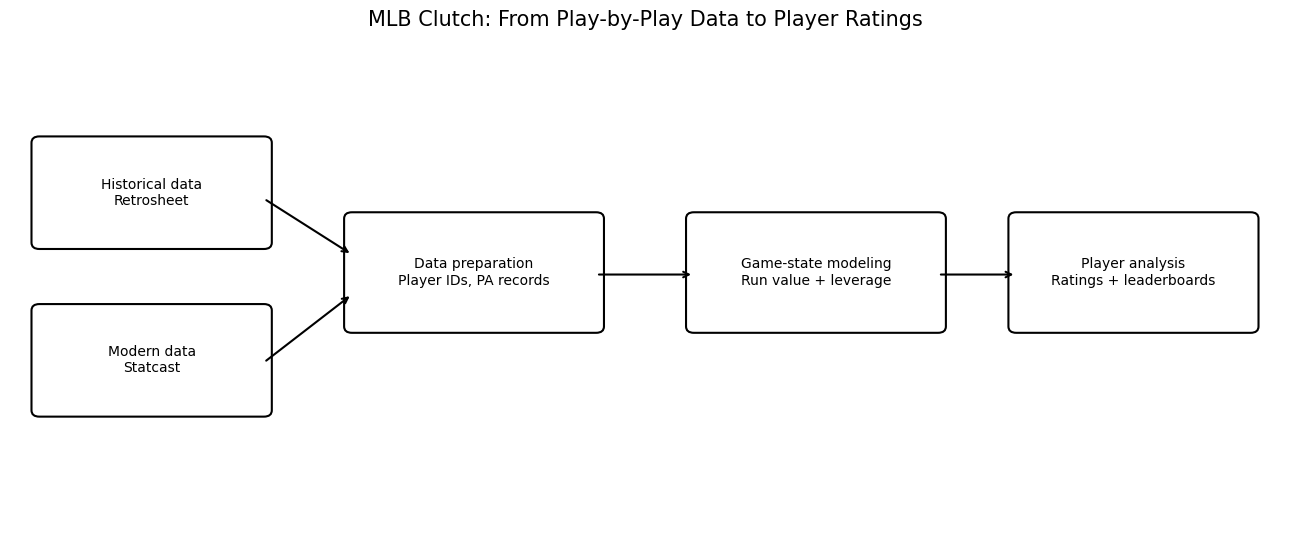

In [122]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(13, 5.5))

ax.set_xlim(0, 13)
ax.set_ylim(0, 6)
ax.axis("off")

boxes = [
    (0.3, 3.6, 2.3, 1.25, "Historical data\nRetrosheet"),
    (0.3, 1.5, 2.3, 1.25, "Modern data\nStatcast"),
    (3.5, 2.55, 2.5, 1.35, "Data preparation\nPlayer IDs, PA records"),
    (7.0, 2.55, 2.5, 1.35, "Game-state modeling\nRun value + leverage"),
    (10.3, 2.55, 2.4, 1.35, "Player analysis\nRatings + leaderboards"),
]

for x, y, w, h, label in boxes:
    patch = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.08",
        linewidth=1.5,
        edgecolor="black",
        facecolor="white"
    )
    ax.add_patch(patch)
    ax.text(
        x + w / 2, y + h / 2, label,
        ha="center", va="center", fontsize=10
    )

arrows = [
    ((2.6, 4.15), (3.5, 3.45)),
    ((2.6, 2.1), (3.5, 2.95)),
    ((6.0, 3.2), (7.0, 3.2)),
    ((9.5, 3.2), (10.3, 3.2)),
]

for start, end in arrows:
    ax.annotate(
        "",
        xy=end,
        xytext=start,
        arrowprops=dict(arrowstyle="->", linewidth=1.5)
    )

ax.set_title(
    "MLB Clutch: From Play-by-Play Data to Player Ratings",
    fontsize=15,
    pad=18
)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "mlb_clutch_pipeline.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

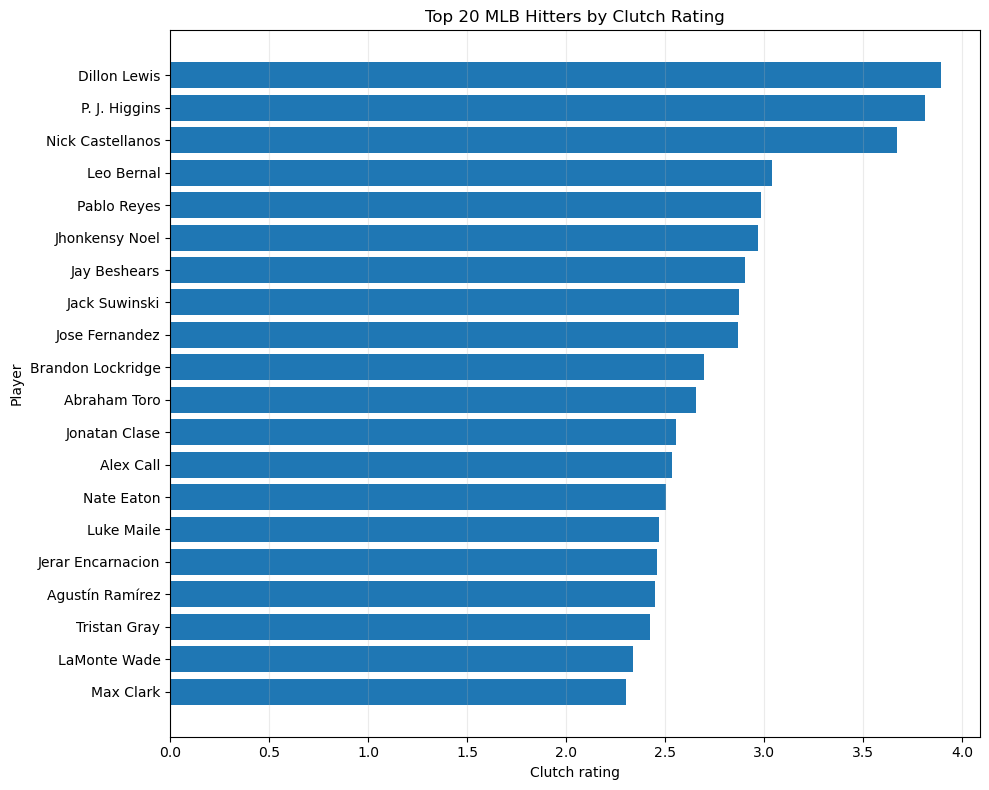

In [124]:
# Keep hitters only
hitter_summary = summary[
    summary["role"].astype(str).str.lower().eq("hitter")
].copy()

hitter_summary["clutch_rating"] = pd.to_numeric(
    hitter_summary["clutch_rating"],
    errors="coerce"
)

hitter_summary = hitter_summary.dropna(
    subset=["player_name", "clutch_rating"]
)

# Do not publish a meaningless ranking if the metric is still broken
if hitter_summary["clutch_rating"].nunique() < 2:
    print(
        "The clutch ratings do not vary enough to make a useful leaderboard. "
        "Validate the leverage join and rating calculations first."
    )
else:
    top20 = hitter_summary.sort_values(
        "clutch_rating", ascending=False
    ).head(20).sort_values("clutch_rating")

    fig, ax = plt.subplots(figsize=(10, 8))

    ax.barh(
        top20["player_name"],
        top20["clutch_rating"]
    )

    ax.set_title("Top 20 MLB Hitters by Clutch Rating")
    ax.set_xlabel("Clutch rating")
    ax.set_ylabel("Player")
    ax.grid(axis="x", alpha=0.25)

    fig.tight_layout()
    fig.savefig(
        FIGURES_DIR / "top_20_clutch_hitters.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

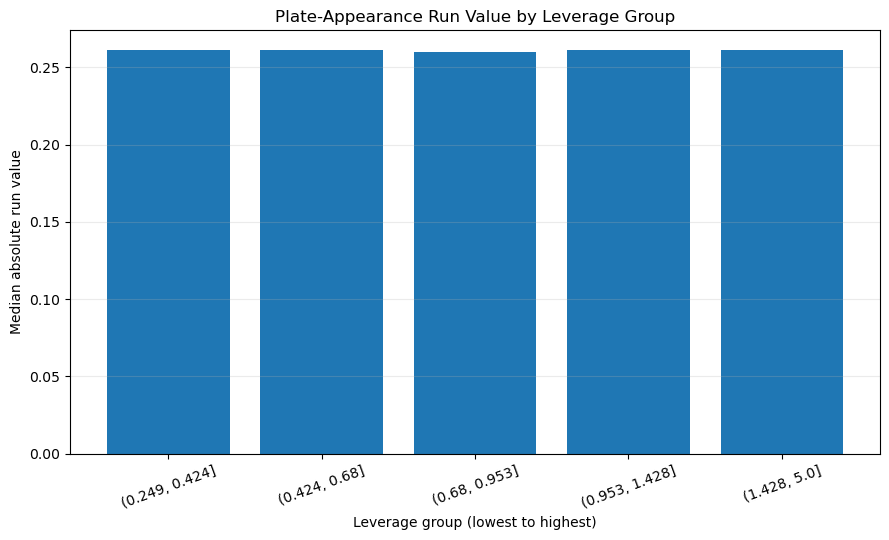

,leverage_group,median_absolute_run_value,plate_appearances
0,"(0.249, 0.424]",0.261,39214
1,"(0.424, 0.68]",0.261,39244
2,"(0.68, 0.953]",0.260,39174
3,"(0.953, 1.428]",0.261,39220
4,"(1.428, 5.0]",0.261,39185


In [126]:
# Pull the required columns from DuckDB
pa_plot = con.sql("""
    SELECT leverage_index, run_value
    FROM pa
    WHERE leverage_index IS NOT NULL
      AND run_value IS NOT NULL
""").df()

pa_plot["leverage_index"] = pd.to_numeric(
    pa_plot["leverage_index"], errors="coerce"
)
pa_plot["run_value"] = pd.to_numeric(
    pa_plot["run_value"], errors="coerce"
)

pa_plot = pa_plot.dropna(
    subset=["leverage_index", "run_value"]
)

# Absolute run value measures the size of the play's effect,
# regardless of whether it helped or hurt the hitter.
pa_plot["absolute_run_value"] = pa_plot["run_value"].abs()

# Split plate appearances into five leverage groups
pa_plot["leverage_group"] = pd.qcut(
    pa_plot["leverage_index"],
    q=5,
    duplicates="drop"
)

leverage_summary = (
    pa_plot.groupby("leverage_group", observed=True)
    .agg(
        median_absolute_run_value=("absolute_run_value", "median"),
        plate_appearances=("run_value", "size")
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.bar(
    leverage_summary["leverage_group"].astype(str),
    leverage_summary["median_absolute_run_value"]
)

ax.set_title("Plate-Appearance Run Value by Leverage Group")
ax.set_xlabel("Leverage group (lowest to highest)")
ax.set_ylabel("Median absolute run value")
ax.tick_params(axis="x", labelrotation=20)
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "run_value_by_leverage.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

display(leverage_summary)

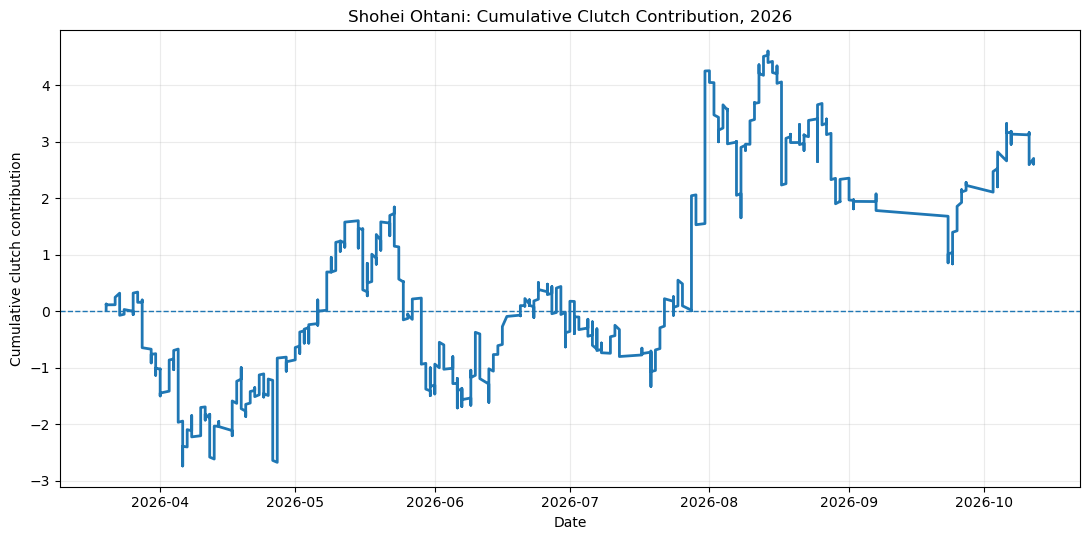

In [128]:
PLAYER_NAME = "Shohei Ohtani"
SEASON = 2026

player_pa = con.execute("""
    SELECT
        player_name,
        game_date,
        game_id,
        season_pa_number,
        clutch_contribution
    FROM player_pa_clutch
    WHERE LOWER(player_name) LIKE LOWER(?)
      AND role = 'hitter'
      AND season = ?
    ORDER BY game_date, game_id, season_pa_number
""", [f"%{PLAYER_NAME}%", SEASON]).df()

player_pa["clutch_contribution"] = pd.to_numeric(
    player_pa["clutch_contribution"],
    errors="coerce"
)

player_pa = player_pa.dropna(
    subset=["game_date", "clutch_contribution"]
).copy()

# Stop rather than create a misleading flat chart if the metric
# is still returning zero contributions.
if (
    player_pa.empty
    or player_pa["clutch_contribution"].abs().sum() < 1e-9
):
    print(
        "No meaningful clutch contributions found. "
        "Validate the leverage join and contribution formula first."
    )
else:
    player_pa["game_date"] = pd.to_datetime(
        player_pa["game_date"]
    )

    player_pa = player_pa.sort_values(
        ["game_date", "game_id", "season_pa_number"]
    )

    player_pa["cumulative_clutch_contribution"] = (
        player_pa["clutch_contribution"].cumsum()
    )

    fig, ax = plt.subplots(figsize=(11, 5.5))

    ax.plot(
        player_pa["game_date"],
        player_pa["cumulative_clutch_contribution"],
        linewidth=2
    )

    ax.axhline(0, linewidth=1, linestyle="--")
    ax.set_title(
        f"{PLAYER_NAME}: Cumulative Clutch Contribution, {SEASON}"
    )
    ax.set_xlabel("Date")
    ax.set_ylabel("Cumulative clutch contribution")
    ax.grid(alpha=0.25)

    fig.tight_layout()
    fig.savefig(
        FIGURES_DIR / "player_clutch_trajectory.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()